In [5]:
# Install TensorFlow

import sys
!{sys.executable} -m pip install tensorflow

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 2.4/384.1 MB 11.3 MB/s eta 0:00:34
   ---------------------------------------- 4.5/384.1 MB 10.8 MB/s eta 0:00:36
    --------------------------------------- 6.3/384.1 MB 9.7 MB/s eta 0:00:39
    --------------------------------------- 7.6/384.1 MB 8.8 MB/s eta 0:00:43
    --------------------------------------- 9.2/384.1 MB 8.6 MB/s eta 0:00:44
   - -------------------------------------- 11.5/384.1 MB 8.9 MB/s eta 0:00:42
   - -------------------------------------- 13.9/384.1 MB 9.3 MB/s eta 0:00:40
   - -------------------------------------- 15.7/384.1 MB 9.1 MB/s eta 0:00:41
   - -------------------------------------- 17.8/384.1 MB 9.1 MB/s eta 0:00:41
   -- ------------------------------------- 19.4/384.1 MB 9.0 MB/s eta 0:00:41
   -- ------------------------------------- 21.8/384.1 MB 9.1 MB/s eta 0:00:40
   -- ------------------------------------- 24.1/384.1 MB 9.3 M

In [6]:
# Import all required libraries for SDNET2018 EDA and preprocessing

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.22.0-rc0


In [7]:
# Set the path of the SDNET2018 dataset

dataset_path = r"C:\Users\USER\Documents\Bridge Monitoring System Project\DATA_Maguire_20180517_ALL"

print("Dataset path:", dataset_path)

Dataset path: C:\Users\USER\Documents\Bridge Monitoring System Project\DATA_Maguire_20180517_ALL


In [8]:
# Display the folders and files present in the SDNET2018 dataset

items = os.listdir(dataset_path)

print("Items inside dataset folder:")
for item in items:
    print(item)

Items inside dataset folder:
D
P
ReadMe_SDNET2018 .txt
W


In [9]:
# Display the contents of the Deck folder

deck_path = os.path.join(dataset_path, "D")

print("Items inside Deck folder:")
for item in os.listdir(deck_path):
    print(item)

Items inside Deck folder:
CD
UD


EDA

In [11]:
# Count the number of cracked and uncracked deck images

cracked_path = os.path.join(deck_path, "CD")
uncracked_path = os.path.join(deck_path, "UD")

cracked_images = os.listdir(cracked_path)
uncracked_images = os.listdir(uncracked_path)

print("Cracked Deck Images:", len(cracked_images))
print("Uncracked Deck Images:", len(uncracked_images))
print("Total Deck Images:", len(cracked_images) + len(uncracked_images))

Cracked Deck Images: 2025
Uncracked Deck Images: 11595
Total Deck Images: 13620


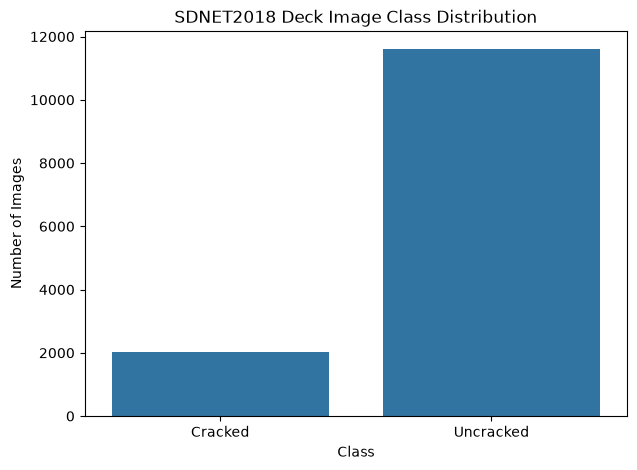

In [12]:
# Visualize the distribution of cracked and uncracked deck images

labels = ["Cracked", "Uncracked"]
counts = [len(cracked_images), len(uncracked_images)]

plt.figure(figsize=(7, 5))
sns.barplot(x=labels, y=counts)
plt.title("SDNET2018 Deck Image Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

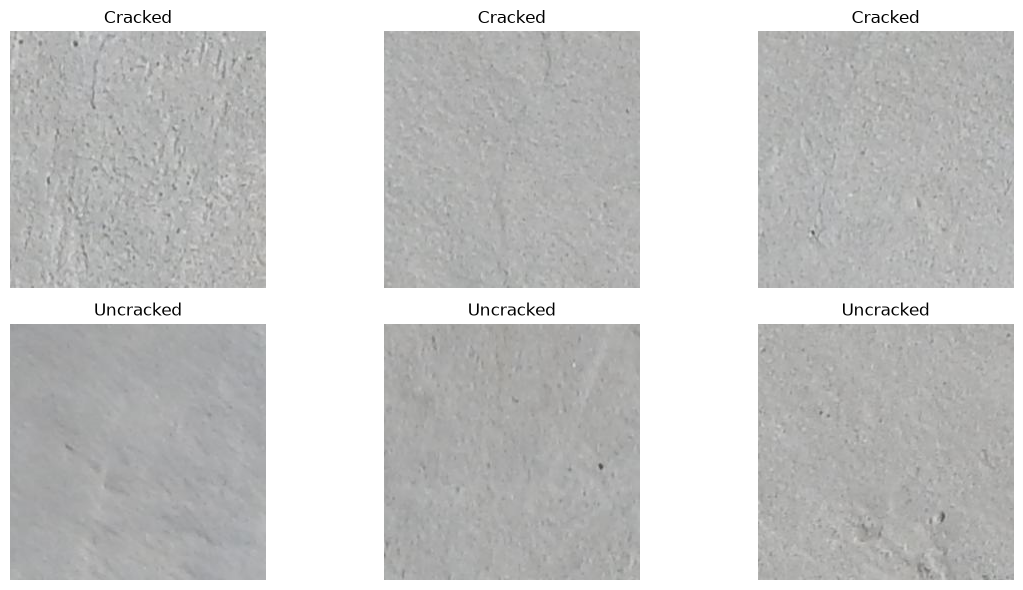

In [13]:
# Display sample cracked and uncracked deck images

plt.figure(figsize=(12, 6))

for i in range(3):
    img = Image.open(os.path.join(cracked_path, cracked_images[i]))
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title("Cracked")
    plt.axis("off")

for i in range(3):
    img = Image.open(os.path.join(uncracked_path, uncracked_images[i]))
    plt.subplot(2, 3, i + 4)
    plt.imshow(img)
    plt.title("Uncracked")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Check the dimensions of sample cracked and uncracked images

sample_images = [
    os.path.join(cracked_path, cracked_images[0]),
    os.path.join(cracked_path, cracked_images[1]),
    os.path.join(uncracked_path, uncracked_images[0]),
    os.path.join(uncracked_path, uncracked_images[1])
]

for image_path in sample_images:
    img = Image.open(image_path)
    print(os.path.basename(image_path), "-> Size:", img.size, "| Mode:", img.mode)

7001-115.jpg -> Size: (256, 256) | Mode: RGB
7001-139.jpg -> Size: (256, 256) | Mode: RGB
7001-1.jpg -> Size: (256, 256) | Mode: RGB
7001-10.jpg -> Size: (256, 256) | Mode: RGB


In [15]:
# Analyze image dimensions across multiple cracked and uncracked images

dimensions = []

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path)[:100]:
        image_path = os.path.join(folder_path, filename)
        img = Image.open(image_path)
        dimensions.append(img.size)

dimension_counts = pd.Series(dimensions).value_counts()

print("Image dimension distribution:")
print(dimension_counts)

Image dimension distribution:
(256, 256)    200
Name: count, dtype: int64


In [16]:
# Check the file formats present in the deck image dataset

all_files = cracked_images + uncracked_images

extensions = [os.path.splitext(filename)[1].lower() for filename in all_files]

format_counts = pd.Series(extensions).value_counts()

print("Image file format distribution:")
print(format_counts)

Image file format distribution:
.jpg    13620
Name: count, dtype: int64


In [19]:
# Check for corrupted or unreadable images

corrupted_images = []

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path):
        image_path = os.path.join(folder_path, filename)
        
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(image_path)

print("Total corrupted/unreadable images:", len(corrupted_images))

if len(corrupted_images) > 0:
    print("\nCorrupted images:")
    for image in corrupted_images[:10]:
        print(image)
else:
    print("No corrupted images found.")

Total corrupted/unreadable images: 0
No corrupted images found.


In [20]:
# Check for duplicate image files using file hashes

import hashlib

image_hashes = {}
duplicate_images = []

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path):
        image_path = os.path.join(folder_path, filename)

        with open(image_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in image_hashes:
            duplicate_images.append((image_path, image_hashes[file_hash]))
        else:
            image_hashes[file_hash] = image_path

print("Total duplicate images:", len(duplicate_images))

if duplicate_images:
    print("\nFirst 10 duplicate pairs:")
    for pair in duplicate_images[:10]:
        print(pair)
else:
    print("No duplicate images found.")

Total duplicate images: 12

First 10 duplicate pairs:
('C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-110_2.jpg', 'C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-110.jpg')
('C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-111_2.jpg', 'C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-111.jpg')
('C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-113_2.jpg', 'C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-113.jpg')
('C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\UD\\7039-112_2.jpg', 'C:\\Users\\USER\\Documents\\Bridge Monitoring System Project\\DATA_Maguire_20180517_ALL\\D\\CD\\7039-112.jpg')
('C:\\Users\\USER\\Documents\\Bridge M

In [21]:
# Analyze pixel intensity statistics of sample deck images

pixel_stats = []

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path)[:100]:
        image_path = os.path.join(folder_path, filename)
        
        img = np.array(Image.open(image_path))
        
        pixel_stats.append({
            "Image": filename,
            "Minimum": img.min(),
            "Maximum": img.max(),
            "Mean": img.mean(),
            "Standard Deviation": img.std()
        })

pixel_stats_df = pd.DataFrame(pixel_stats)

print(pixel_stats_df.head())
print("\nOverall Pixel Statistics:")
print(pixel_stats_df[["Minimum", "Maximum", "Mean", "Standard Deviation"]].describe())

          Image  Minimum  Maximum        Mean  Standard Deviation
0  7001-115.jpg       90      225  178.787898            9.905552
1  7001-139.jpg      124      208  175.889959            5.737498
2  7001-151.jpg       74      224  179.074534            7.143125
3  7001-157.jpg      118      205  175.024165            6.259188
4  7001-169.jpg      120      211  179.181681            6.339968

Overall Pixel Statistics:
          Minimum     Maximum        Mean  Standard Deviation
count  200.000000  200.000000  200.000000          200.000000
mean    91.980000  213.120000  176.664201            7.724815
std     32.079982    8.950764    7.056821            3.732381
min      5.000000  192.000000  106.920003            3.545078
25%     71.750000  207.000000  174.768068            5.759119
50%     98.000000  212.000000  177.529124            6.821748
75%    118.000000  218.000000  180.039191            8.454609
max    153.000000  243.000000  188.974792           31.901248


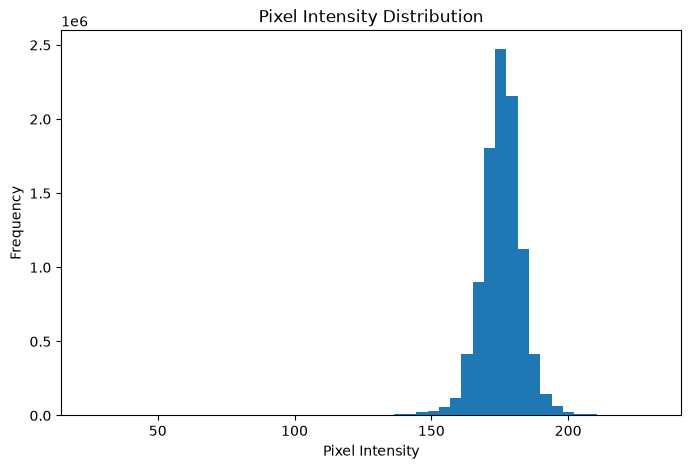

In [22]:
# Plot the pixel intensity distribution of sample deck images

sample_pixels = []

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path)[:25]:
        image_path = os.path.join(folder_path, filename)
        img = np.array(Image.open(image_path))
        sample_pixels.extend(img.flatten())

plt.figure(figsize=(8, 5))
plt.hist(sample_pixels, bins=50)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

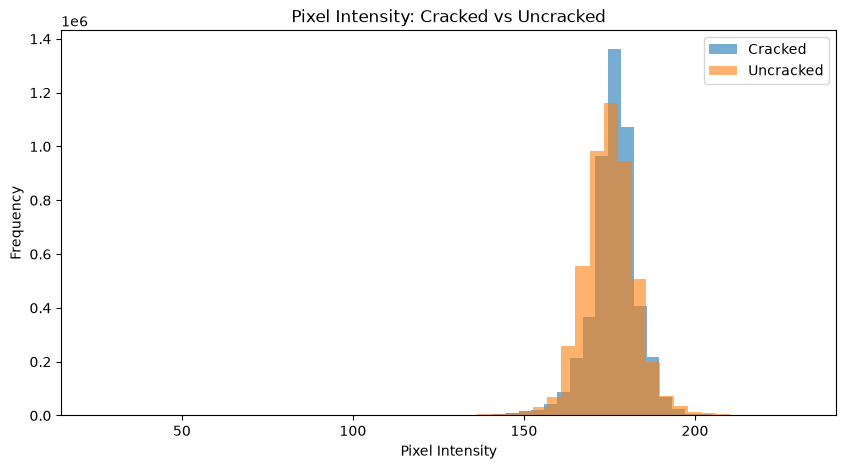

In [25]:
# Compare pixel intensity distributions of cracked and uncracked images

cracked_pixels = []
uncracked_pixels = []

for filename in cracked_images[:25]:
    img = np.array(Image.open(os.path.join(cracked_path, filename)))
    cracked_pixels.extend(img.flatten())

for filename in uncracked_images[:25]:
    img = np.array(Image.open(os.path.join(uncracked_path, filename)))
    uncracked_pixels.extend(img.flatten())

plt.figure(figsize=(10, 5))

plt.hist(cracked_pixels, bins=50, alpha=0.6, label="Cracked")
plt.hist(uncracked_pixels, bins=50, alpha=0.6, label="Uncracked")

plt.title("Pixel Intensity: Cracked vs Uncracked")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [26]:
# Compare average pixel intensity between cracked and uncracked images

class_stats = []

for class_name, folder_path, filenames in [
    ("Cracked", cracked_path, cracked_images[:100]),
    ("Uncracked", uncracked_path, uncracked_images[:100])
]:
    for filename in filenames:
        image_path = os.path.join(folder_path, filename)
        img = np.array(Image.open(image_path))

        class_stats.append({
            "Class": class_name,
            "Mean Pixel": img.mean(),
            "Std Pixel": img.std()
        })

class_stats_df = pd.DataFrame(class_stats)

print(class_stats_df.groupby("Class").mean())

           Mean Pixel  Std Pixel
Class                           
Cracked    178.437505   8.106166
Uncracked  174.890897   7.343464


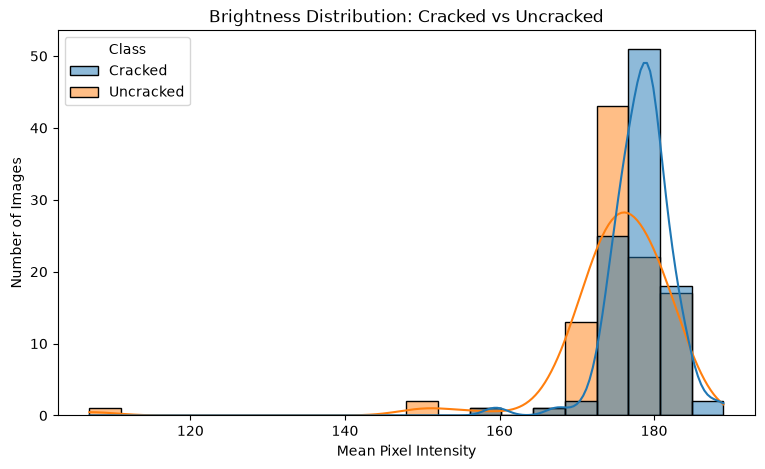

In [27]:
# Plot the brightness distribution of cracked and uncracked images

plt.figure(figsize=(9, 5))

sns.histplot(
    data=class_stats_df,
    x="Mean Pixel",
    hue="Class",
    bins=20,
    kde=True
)

plt.title("Brightness Distribution: Cracked vs Uncracked")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.show()

In [28]:
# Analyze average RGB channel intensity for cracked and uncracked images

rgb_stats = []

for class_name, folder_path, filenames in [
    ("Cracked", cracked_path, cracked_images[:100]),
    ("Uncracked", uncracked_path, uncracked_images[:100])
]:
    for filename in filenames:
        image_path = os.path.join(folder_path, filename)
        img = np.array(Image.open(image_path))

        rgb_stats.append({
            "Class": class_name,
            "Red": img[:, :, 0].mean(),
            "Green": img[:, :, 1].mean(),
            "Blue": img[:, :, 2].mean()
        })

rgb_stats_df = pd.DataFrame(rgb_stats)

print(rgb_stats_df.groupby("Class").mean())

                  Red       Green        Blue
Class                                        
Cracked    177.936350  178.657640  178.718526
Uncracked  174.618324  175.199567  174.854800


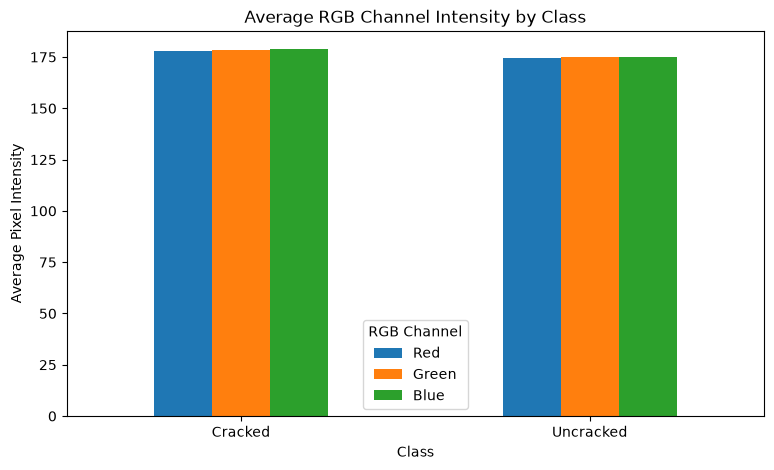

In [29]:
# Visualize average RGB channel intensities for cracked and uncracked images

rgb_mean = rgb_stats_df.groupby("Class")[["Red", "Green", "Blue"]].mean()

rgb_mean.plot(kind="bar", figsize=(9, 5))

plt.title("Average RGB Channel Intensity by Class")
plt.xlabel("Class")
plt.ylabel("Average Pixel Intensity")
plt.xticks(rotation=0)
plt.legend(title="RGB Channel")
plt.show()

In [30]:
# Check image dimensions across the complete deck dataset

dimension_counts = {}

for folder_path in [cracked_path, uncracked_path]:
    for filename in os.listdir(folder_path):
        image_path = os.path.join(folder_path, filename)
        
        try:
            with Image.open(image_path) as img:
                size = img.size
                dimension_counts[size] = dimension_counts.get(size, 0) + 1
        except Exception:
            pass

print("Complete dataset dimension distribution:")

for size, count in sorted(dimension_counts.items(), key=lambda x: x[1], reverse=True):
    print(size, "->", count, "images")

Complete dataset dimension distribution:
(256, 256) -> 13620 images


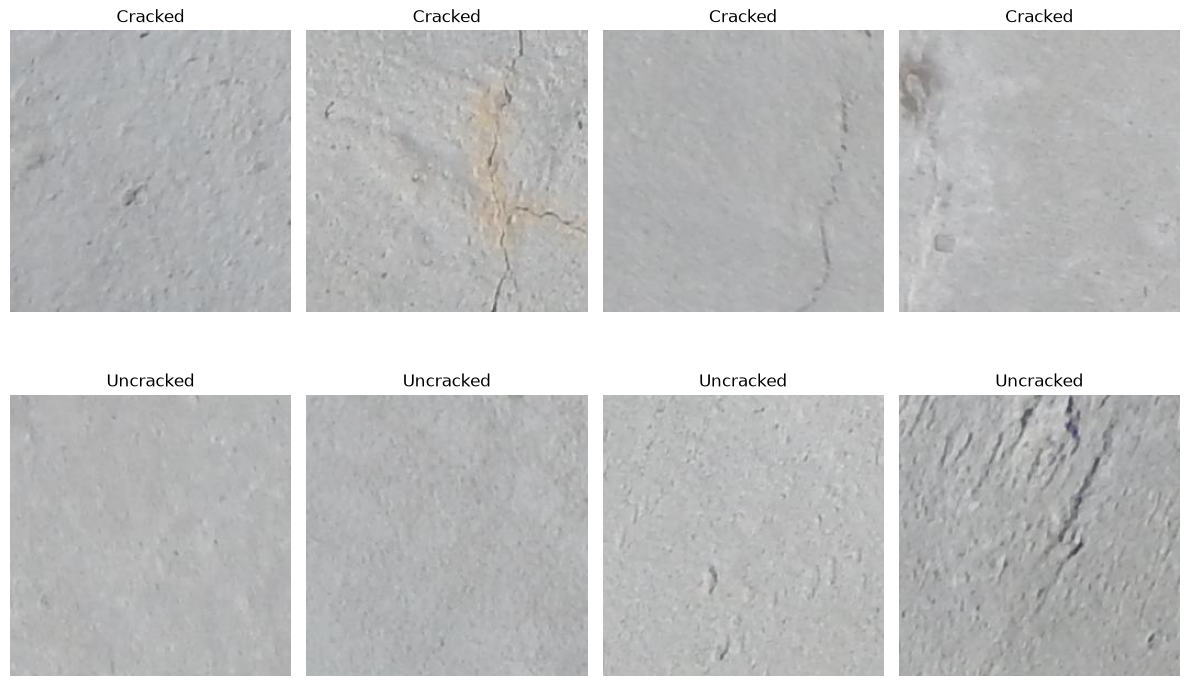

In [31]:
# Display randomly selected cracked and uncracked deck images

import random

random_cracked = random.sample(cracked_images, 4)
random_uncracked = random.sample(uncracked_images, 4)

plt.figure(figsize=(12, 8))

for i, filename in enumerate(random_cracked):
    img = Image.open(os.path.join(cracked_path, filename))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title("Cracked")
    plt.axis("off")

for i, filename in enumerate(random_uncracked):
    img = Image.open(os.path.join(uncracked_path, filename))
    plt.subplot(2, 4, i + 5)
    plt.imshow(img)
    plt.title("Uncracked")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
# Display the final EDA summary of the SDNET2018 deck dataset

total_images = len(cracked_images) + len(uncracked_images)
cracked_percentage = (len(cracked_images) / total_images) * 100
uncracked_percentage = (len(uncracked_images) / total_images) * 100

print("========== SDNET2018 EDA SUMMARY ==========")
print("Total Images       :", total_images)
print("Cracked Deck Images:", len(cracked_images))
print("Uncracked Images   :", len(uncracked_images))
print("Cracked Percentage :", round(cracked_percentage, 2), "%")
print("Uncracked Percentage:", round(uncracked_percentage, 2), "%")
print("Image Size         : 256 x 256")
print("Image Type         : RGB")
print("Duplicate Images   : 12")
print("============================================")

========== SDNET2018 EDA SUMMARY ==========
Total Images       : 13620
Cracked Deck Images: 2025
Uncracked Images   : 11595
Cracked Percentage : 14.87 %
Uncracked Percentage: 85.13 %
Image Size         : 256 x 256
Image Type         : RGB
Duplicate Images   : 12


Preprocessing

In [33]:
# Create a DataFrame containing image paths and their corresponding labels

image_data = []

# Add cracked images with label 1
for filename in cracked_images:
    image_data.append({
        "Image_Path": os.path.join(cracked_path, filename),
        "Label": 1,
        "Class": "Cracked"
    })

# Add uncracked images with label 0
for filename in uncracked_images:
    image_data.append({
        "Image_Path": os.path.join(uncracked_path, filename),
        "Label": 0,
        "Class": "Uncracked"
    })

image_df = pd.DataFrame(image_data)

print("Total images:", len(image_df))
print("\nClass distribution:")
print(image_df["Class"].value_counts())

print("\nFirst 5 records:")
print(image_df.head())

Total images: 13620

Class distribution:
Class
Uncracked    11595
Cracked       2025
Name: count, dtype: int64

First 5 records:
                                          Image_Path  Label    Class
0  C:\Users\USER\Documents\Bridge Monitoring Syst...      1  Cracked
1  C:\Users\USER\Documents\Bridge Monitoring Syst...      1  Cracked
2  C:\Users\USER\Documents\Bridge Monitoring Syst...      1  Cracked
3  C:\Users\USER\Documents\Bridge Monitoring Syst...      1  Cracked
4  C:\Users\USER\Documents\Bridge Monitoring Syst...      1  Cracked


In [34]:
# Check whether duplicate images belong to the same class or different classes

duplicate_check = []

for duplicate_path, original_path in duplicate_images:
    duplicate_class = image_df.loc[image_df["Image_Path"] == duplicate_path, "Class"].values[0]
    original_class = image_df.loc[image_df["Image_Path"] == original_path, "Class"].values[0]
    
    duplicate_check.append({
        "Duplicate_Image": os.path.basename(duplicate_path),
        "Original_Image": os.path.basename(original_path),
        "Duplicate_Class": duplicate_class,
        "Original_Class": original_class,
        "Same_Class": duplicate_class == original_class
    })

duplicate_df = pd.DataFrame(duplicate_check)

print("Total duplicate pairs:", len(duplicate_df))
print("\nDuplicate check:")
print(duplicate_df)

print("\nDuplicates with different classes:")
print(duplicate_df[duplicate_df["Same_Class"] == False])

Total duplicate pairs: 12

Duplicate check:
   Duplicate_Image Original_Image Duplicate_Class Original_Class  Same_Class
0   7039-110_2.jpg   7039-110.jpg         Cracked        Cracked        True
1   7039-111_2.jpg   7039-111.jpg         Cracked        Cracked        True
2   7039-113_2.jpg   7039-113.jpg         Cracked        Cracked        True
3   7039-112_2.jpg   7039-112.jpg       Uncracked        Cracked       False
4    7053-17_2.jpg    7053-17.jpg       Uncracked      Uncracked        True
5    7053-18_2.jpg    7053-18.jpg       Uncracked      Uncracked        True
6    7053-35_2.jpg    7053-35.jpg       Uncracked      Uncracked        True
7    7053-36_2.jpg    7053-36.jpg       Uncracked      Uncracked        True
8    7053-53_2.jpg    7053-53.jpg       Uncracked      Uncracked        True
9    7053-54_2.jpg    7053-54.jpg       Uncracked      Uncracked        True
10   7053-89_2.jpg    7053-89.jpg       Uncracked      Uncracked        True
11   7053-90_2.jpg    7053-90.jp

In [36]:
# Remove duplicate images and the conflicting duplicate pair

# Get the duplicate image paths
duplicate_paths = [pair[0] for pair in duplicate_images]

# Find the original image involved in the label conflict
conflict_row = duplicate_df[duplicate_df["Same_Class"] == False].iloc[0]

conflict_duplicate = conflict_row["Duplicate_Image"]
conflict_original = conflict_row["Original_Image"]

# Find the full paths of both conflicting images
conflict_paths = image_df[
    image_df["Image_Path"].str.endswith(conflict_duplicate) |
    image_df["Image_Path"].str.endswith(conflict_original)
]["Image_Path"].tolist()

# Remove duplicate copies and both conflicting images
paths_to_remove = set(duplicate_paths + conflict_paths)

clean_image_df = image_df[
    ~image_df["Image_Path"].isin(paths_to_remove)
].copy()

clean_image_df = clean_image_df.reset_index(drop=True)

print("Original dataset size :", len(image_df))
print("Clean dataset size    :", len(clean_image_df))
print("Images removed        :", len(image_df) - len(clean_image_df))

print("\nClean class distribution:")
print(clean_image_df["Class"].value_counts())

Original dataset size : 13620
Clean dataset size    : 13607
Images removed        : 13

Clean class distribution:
Class
Uncracked    11586
Cracked       2021
Name: count, dtype: int64


In [37]:
# Perform a final quality check on the cleaned dataset before splitting

print("========== FINAL DATASET CHECK ==========")
print("Total images:", len(clean_image_df))
print("\nClass distribution:")
print(clean_image_df["Class"].value_counts())

print("\nMissing values:")
print(clean_image_df.isnull().sum())

print("\nDuplicate file paths:")
print(clean_image_df["Image_Path"].duplicated().sum())

print("\nLabel distribution:")
print(clean_image_df["Label"].value_counts())

print("=========================================")

========== FINAL DATASET CHECK ==========
Total images: 13607

Class distribution:
Class
Uncracked    11586
Cracked       2021
Name: count, dtype: int64

Missing values:
Image_Path    0
Label         0
Class         0
dtype: int64

Duplicate file paths:
0

Label distribution:
Label
0    11586
1     2021
Name: count, dtype: int64


* Train/Validation/Test Split

In [38]:
# Split the cleaned dataset into training, validation, and testing sets

train_df, temp_df = train_test_split(
    clean_image_df,
    test_size=0.30,
    stratify=clean_image_df["Label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Label"],
    random_state=42
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("========== DATASET SPLIT ==========")
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))

print("\nTraining class distribution:")
print(train_df["Class"].value_counts())

print("\nValidation class distribution:")
print(val_df["Class"].value_counts())

print("\nTesting class distribution:")
print(test_df["Class"].value_counts())

========== DATASET SPLIT ==========
Training images   : 9524
Validation images : 2041
Testing images    : 2042

Training class distribution:
Class
Uncracked    8109
Cracked      1415
Name: count, dtype: int64

Validation class distribution:
Class
Uncracked    1738
Cracked       303
Name: count, dtype: int64

Testing class distribution:
Class
Uncracked    1739
Cracked       303
Name: count, dtype: int64


In [39]:
# Calculate class weights to handle the training data imbalance

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["Label"])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["Label"]
)

class_weights = dict(zip(classes, class_weights_array))

print("Class weights:")
print("Uncracked (0):", round(class_weights[0], 4))
print("Cracked (1)  :", round(class_weights[1], 4))

Class weights:
Uncracked (0): 0.5872
Cracked (1)  : 3.3654


In [40]:
# Create TensorFlow datasets from the train, validation, and test DataFrames

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def create_dataset(dataframe, shuffle=False):
    paths = dataframe["Image_Path"].values
    labels = dataframe["Label"].values
    
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(dataframe), seed=42)
    
    def load_image(image_path, label):
        image = tf.io.read_file(image_path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)
        return image, label
    
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully!")
print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)

TensorFlow datasets created successfully!
Image size : (224, 224)
Batch size : 32


In [41]:
# Verify the shape and labels of one training batch

for images, labels in train_ds.take(1):
    print("Image batch shape :", images.shape)
    print("Label batch shape :", labels.shape)
    print("Image data type   :", images.dtype)
    print("First 10 labels   :", labels[:10].numpy())

Image batch shape : (32, 224, 224, 3)
Label batch shape : (32,)
Image data type   : <dtype: 'float32'>
First 10 labels   : [1 0 0 0 0 0 0 0 0 0]


In [42]:
# Create data augmentation layers for training images

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


In [43]:
# Build a CNN-based MobileNetV2 transfer learning model for crack classification

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Create the complete classification model
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)

outputs = keras.layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

print("CNN model created successfully!")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step
CNN model created successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [44]:
# Compile the CNN model for binary crack classification

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [45]:
# Create callbacks to control and save the best training model

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    "best_bridge_crack_model.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Training callbacks created successfully!")

Training callbacks created successfully!


Train the CNN

In [46]:
# Train the CNN model with class weights and validation monitoring

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, model_checkpoint]
)

print("Stage 1 CNN training completed!")

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 660s 2s/step - accuracy: 0.7062 - loss: 0.6157 - val_accuracy: 0.8280 - val_loss: 0.5122
Epoch 2/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 560s 2s/step - accuracy: 0.7859 - loss: 0.5591 - val_accuracy: 0.8721 - val_loss: 0.4470
Epoch 3/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 576s 2s/step - accuracy: 0.8021 - loss: 0.5394 - val_accuracy: 0.8834 - val_loss: 0.4157
Epoch 4/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 572s 2s/step - accuracy: 0.8233 - loss: 0.5200 - val_accuracy: 0.8805 - val_loss: 0.4205
Epoch 5/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 568s 2s/step - accuracy: 0.8161 - loss: 0.5145 - val_accuracy: 0.8917 - val_loss: 0.3900
Epoch 6/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 590s 2s/step - accuracy: 0.8277 - loss: 0.5044 - val_accuracy: 0.8951 - val_loss: 0.3713
Epoch 7/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 565s 2s/step - accuracy: 0.8247 - loss: 0.5007 - val_accuracy: 0.8932 - val_loss: 0.3807
Epoch 8/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 547s 2s/step - accuracy: 0.8261 - loss: 0.4961 - val_accu

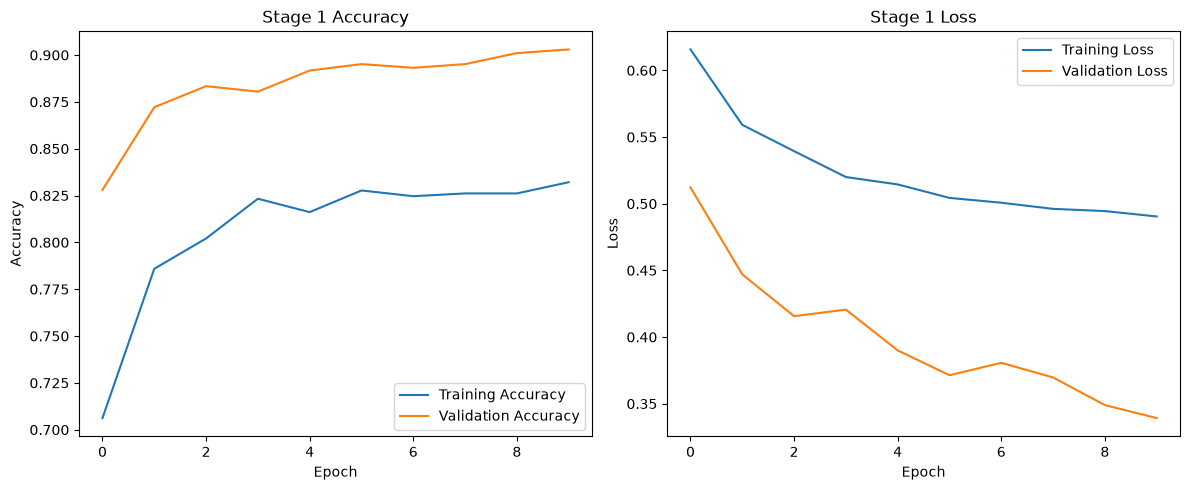

In [47]:
# Plot training and validation accuracy and loss for Stage 1

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Stage 1 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Stage 1 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [48]:
# Unfreeze the top layers of MobileNetV2 for fine-tuning

base_model.trainable = True

# Freeze the earlier layers and keep the last 30 layers trainable
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total MobileNetV2 layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Frozen layers:", sum(not layer.trainable for layer in base_model.layers))

Total MobileNetV2 layers: 154
Trainable layers: 30
Frozen layers: 124


In [49]:
# Recompile the model with a very small learning rate for fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled successfully for fine-tuning!")
print("Fine-tuning learning rate: 0.00001")

Model recompiled successfully for fine-tuning!
Fine-tuning learning rate: 0.00001


In [50]:
# Check whether the trained model file was saved successfully

import os

model_file = "best_bridge_crack_model.keras"

if os.path.exists(model_file):
    print("Trained model found!")
    print("Model path:", os.path.abspath(model_file))
    print("Model size:", round(os.path.getsize(model_file) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found.")

Trained model found!
Model path: C:\Users\USER\best_bridge_crack_model.keras
Model size: 9.2 MB


In [51]:
# Fine-tune the CNN model with the top MobileNetV2 layers unfrozen

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, model_checkpoint]
)

print("Stage 2 fine-tuning completed!")

Epoch 1/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 816s 3s/step - accuracy: 0.8118 - loss: 0.4923 - val_accuracy: 0.9040 - val_loss: 0.3248
Epoch 2/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 685s 2s/step - accuracy: 0.8327 - loss: 0.4750 - val_accuracy: 0.9049 - val_loss: 0.3227
Epoch 3/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 656s 2s/step - accuracy: 0.8404 - loss: 0.4628 - val_accuracy: 0.9069 - val_loss: 0.3394
Epoch 4/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 6357s 21s/step - accuracy: 0.8408 - loss: 0.4557 - val_accuracy: 0.9206 - val_loss: 0.2856
Epoch 5/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 639s 2s/step - accuracy: 0.8508 - loss: 0.4460 - val_accuracy: 0.9172 - val_loss: 0.2661
Epoch 6/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 1323s 4s/step - accuracy: 0.8563 - loss: 0.4445 - val_accuracy: 0.9064 - val_loss: 0.3271
Epoch 7/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 611s 2s/step - accuracy: 0.8563 - loss: 0.4329 - val_accuracy: 0.9015 - val_loss: 0.3395
Epoch 8/10
298/298 ━━━━━━━━━━━━━━━━━━━━ 605s 2s/step - accuracy: 0.8632 - loss: 0.4320 - val_a

In [52]:
# Save the final fine-tuned bridge crack detection model

final_model_path = r"C:\Users\USER\bridge_crack_final_model.keras"

model.save(final_model_path)

print("Final model saved successfully!")
print("Model path:", final_model_path)
print("Model size:", round(os.path.getsize(final_model_path) / (1024 * 1024), 2), "MB")

Final model saved successfully!
Model path: C:\Users\USER\bridge_crack_final_model.keras
Model size: 20.87 MB


In [53]:
# Evaluate the final fine-tuned model on the unseen test dataset

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

64/64 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.9104 - loss: 0.2826
Test Loss: 0.2826
Test Accuracy: 91.04 %


In [54]:
# Generate predictions and calculate precision, recall, and F1-score

y_true = test_df["Label"].values
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Uncracked", "Cracked"]
))

64/64 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step
Classification Report:

              precision    recall  f1-score   support

   Uncracked       0.93      0.97      0.95      1739
     Cracked       0.77      0.57      0.65       303

    accuracy                           0.91      2042
   macro avg       0.85      0.77      0.80      2042
weighted avg       0.90      0.91      0.90      2042



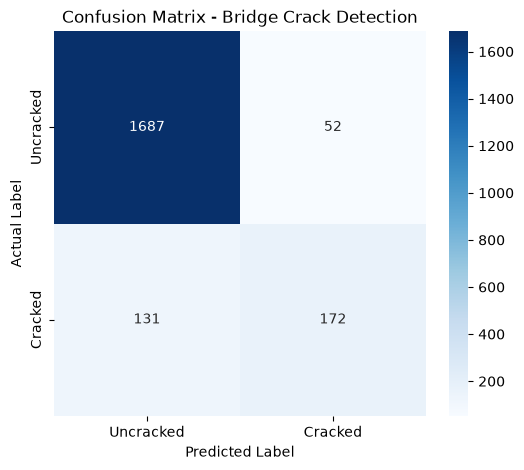

Confusion Matrix:
[[1687   52]
 [ 131  172]]


In [55]:
# Display the confusion matrix for the bridge crack detection model

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uncracked", "Cracked"],
    yticklabels=["Uncracked", "Cracked"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Bridge Crack Detection")
plt.show()

print("Confusion Matrix:")
print(cm)

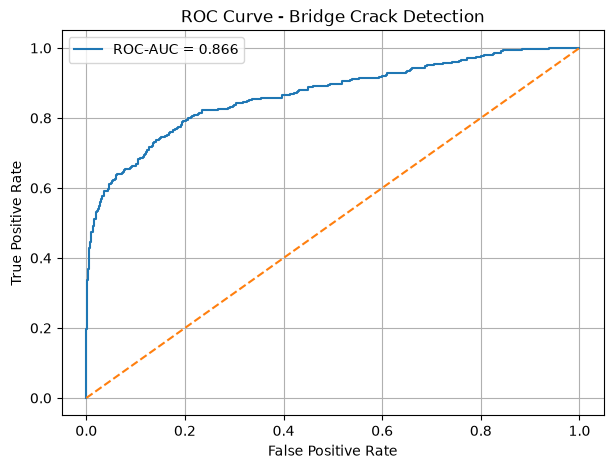

ROC-AUC Score: 0.8664


In [56]:
# Calculate and plot the ROC curve and AUC score

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Bridge Crack Detection")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

In [57]:
# Find the threshold that gives the best F1-score for cracked images

from sklearn.metrics import precision_recall_curve

precision, recall, threshold_values = precision_recall_curve(y_true, y_prob)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

best_index = np.argmax(f1_scores)
best_threshold = threshold_values[best_index]

print("Best Threshold:", round(best_threshold, 3))
print("Best Cracked Precision:", round(precision[best_index], 3))
print("Best Cracked Recall:", round(recall[best_index], 3))
print("Best Cracked F1-score:", round(f1_scores[best_index], 3))

Best Threshold: 0.452
Best Cracked Precision: 0.737
Best Cracked Recall: 0.591
Best Cracked F1-score: 0.656


In [58]:
# Store the selected classification threshold for the final bridge crack detection system

CRACK_THRESHOLD = 0.452

print("Final crack detection threshold:", CRACK_THRESHOLD)

Final crack detection threshold: 0.452


In [59]:
# Predict crack status for a single bridge deck image

image_path = test_df.iloc[0]["Image_Path"]

img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

if prediction >= CRACK_THRESHOLD:
    predicted_class = "Cracked"
    confidence = prediction
else:
    predicted_class = "Uncracked"
    confidence = 1 - prediction

print("Image:", os.path.basename(image_path))
print("Prediction:", predicted_class)
print("Confidence:", round(confidence * 100, 2), "%")

Image: 7019-102.jpg
Prediction: Uncracked
Confidence: 81.59 %


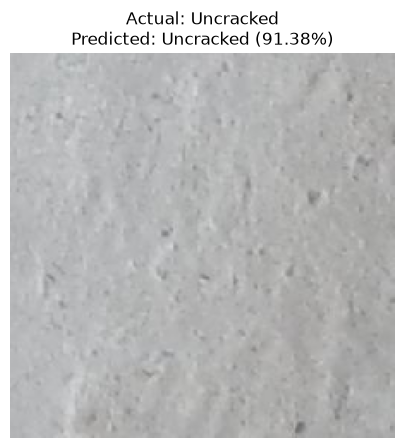

Image: 7020-195.jpg
Actual Class: Uncracked
Predicted Class: Uncracked
Confidence: 91.38 %


In [60]:
# Display a random test image with its actual and predicted class

sample = test_df.sample(1, random_state=42).iloc[0]

image_path = sample["Image_Path"]
actual_class = "Cracked" if sample["Label"] == 1 else "Uncracked"

img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
img_array = tf.keras.utils.img_to_array(img)
img_input = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_input, verbose=0)[0][0]

if prediction >= CRACK_THRESHOLD:
    predicted_class = "Cracked"
    confidence = prediction
else:
    predicted_class = "Uncracked"
    confidence = 1 - prediction

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class} ({confidence * 100:.2f}%)"
)
plt.show()

print("Image:", os.path.basename(image_path))
print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence * 100, 2), "%")

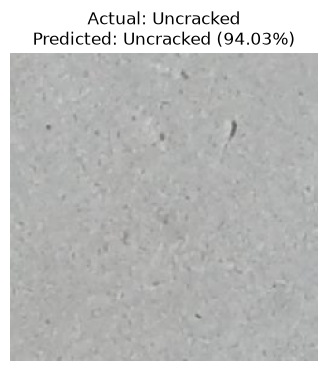

Image: 7043-139.jpg
Actual: Uncracked
Predicted: Uncracked
Confidence: 94.03 %
--------------------------------------------------


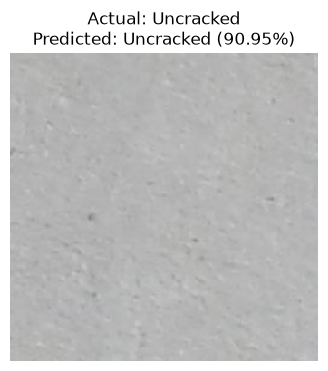

Image: 7012-92.jpg
Actual: Uncracked
Predicted: Uncracked
Confidence: 90.95 %
--------------------------------------------------


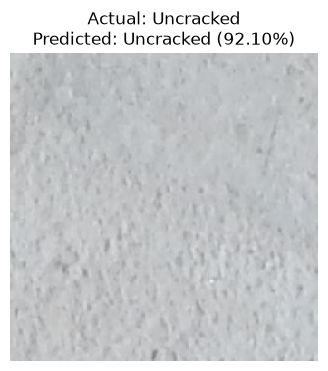

Image: 7033-247.jpg
Actual: Uncracked
Predicted: Uncracked
Confidence: 92.1 %
--------------------------------------------------


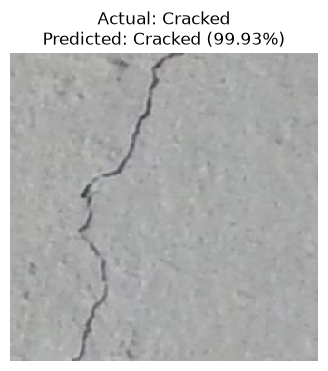

Image: 7011-125.jpg
Actual: Cracked
Predicted: Cracked
Confidence: 99.93 %
--------------------------------------------------


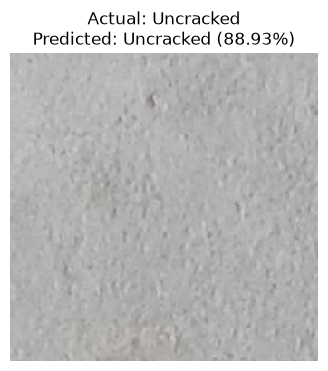

Image: 7040-80.jpg
Actual: Uncracked
Predicted: Uncracked
Confidence: 88.93 %
--------------------------------------------------


In [61]:
# Test the model on five random images from the unseen test dataset

sample_df = test_df.sample(5, random_state=10)

for _, row in sample_df.iterrows():
    image_path = row["Image_Path"]
    actual_class = "Cracked" if row["Label"] == 1 else "Uncracked"

    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_input = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_input, verbose=0)[0][0]

    if prediction >= CRACK_THRESHOLD:
        predicted_class = "Cracked"
        confidence = prediction
    else:
        predicted_class = "Uncracked"
        confidence = 1 - prediction

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class} ({confidence * 100:.2f}%)"
    )
    plt.show()

    print("Image:", os.path.basename(image_path))
    print("Actual:", actual_class)
    print("Predicted:", predicted_class)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 50)

In [62]:
# Create a reusable function for bridge crack prediction

def predict_bridge_crack(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_input = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_input, verbose=0)[0][0]

    if prediction >= CRACK_THRESHOLD:
        predicted_class = "Cracked"
        confidence = prediction
    else:
        predicted_class = "Uncracked"
        confidence = 1 - prediction

    return predicted_class, confidence

In [63]:
# Verify the reusable bridge crack prediction function on a test image

test_image = test_df.iloc[10]["Image_Path"]

predicted_class, confidence = predict_bridge_crack(test_image)

print("Image:", os.path.basename(test_image))
print("Prediction:", predicted_class)
print("Confidence:", round(confidence * 100, 2), "%")

Image: 7018-61.jpg
Prediction: Uncracked
Confidence: 88.86 %


In [64]:
# Check whether Streamlit is installed

import sys
!{sys.executable} -m pip show streamlit

Name: streamlit
Version: 1.58.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: 
Author-email: Snowflake Inc <hello@streamlit.io>
License-Expression: Apache-2.0
Location: C:\Users\USER\anaconda3\Lib\site-packages
Requires: altair, anyio, blinker, cachetools, click, gitpython, httptools, itsdangerous, numpy, packaging, pandas, pillow, protobuf, pyarrow, python-multipart, requests, starlette, tenacity, toml, typing-extensions, uvicorn, watchdog, websockets
Required-by: 


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:

# Cell 2: Load the NBI bridge parameter dataset

file_path = r"C:\Users\USER\Downloads\bridge_data.csv.xlsx"

bridge_df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", bridge_df.shape)

print("\nColumn names:")
print(bridge_df.columns.tolist())

display(bridge_df.head())


Dataset loaded successfully!
Dataset shape: (10000, 21)

Column names:
['Bridge_ID', 'Location', 'Age (years)', 'Material', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Weather_Conditions', 'Water_Flow_Rate (mÂ³/s)', 'Maintenance_History', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Material_Composition', 'Bridge_Design', 'Construction_Quality', 'Temperature (Â°C)', 'Humidity (%)', 'Collapse_Status']


,Bridge_ID,Location,Age (years),Material,Length (m),Width (m),Height (m),Traffic_Volume (vehicles/day),Weather_Conditions,Water_Flow_Rate (mÂ³/s),...,Stress (MPa),Strain (%),Tensile_Strength (MPa),Rainfall (mm),Material_Composition,Bridge_Design,Construction_Quality,Temperature (Â°C),Humidity (%),Collapse_Status
0,1,Region_1,26,Steel,50.000000,5.000000,10.000000,100.000000,Rainy,0.00000,...,0.000000,0.000,200.000000,0.000000,"Steel 70%, Concrete 30%",Arch,Good,-30.000000,0.000000,Standing
1,2,Region_2,47,Concrete,50.195020,5.004500,10.009001,100.990099,Sunny,0.50005,...,0.010001,0.001,200.080008,0.050005,"Concrete 80%, Wood 20%",Beam,Good,-29.991999,0.010001,Standing
2,3,Region_3,1,Wood,50.390039,5.009001,10.018002,101.980198,Snowy,1.00010,...,0.020002,0.002,200.160016,0.100010,"Concrete 80%, Wood 20%",Truss,Good,-29.983998,0.020002,Standing
3,4,Region_4,32,Steel,50.585059,5.013501,10.027003,102.970297,Cloudy,1.50015,...,0.030003,0.003,200.240024,0.150015,"Steel 70%, Concrete 30%",Arch,Good,-29.975998,0.030003,Standing
4,5,Region_5,27,Concrete,50.780078,5.018002,10.036004,103.960396,Windy,2.00020,...,0.040004,0.004,200.320032,0.200020,"Concrete 80%, Wood 20%",Beam,Good,-29.967997,0.040004,Standing


In [10]:

# Cell 3: Check dataset structure and data types

print("Dataset Information:\n")
bridge_df.info()

print("\nDataset shape:", bridge_df.shape)

print("\nData types of each column:")
display(bridge_df.dtypes.to_frame(name="Data Type"))


Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Bridge_ID                      10000 non-null  int64         
 1   Location                       10000 non-null  str           
 2   Age (years)                    10000 non-null  int64         
 3   Material                       10000 non-null  str           
 4   Length (m)                     10000 non-null  float64       
 5   Width (m)                      10000 non-null  float64       
 6   Height (m)                     10000 non-null  float64       
 7   Traffic_Volume (vehicles/day)  10000 non-null  float64       
 8   Weather_Conditions             10000 non-null  str           
 9   Water_Flow_Rate (mÂ³/s)        10000 non-null  float64       
 10  Maintenance_History            10000 non-null  datetime64[us]
 11  Stres

,Data Type
Bridge_ID,int64
Location,str
Age (years),int64
Material,str
Length (m),float64
Width (m),float64
Height (m),float64
Traffic_Volume (vehicles/day),float64
Weather_Conditions,str
Water_Flow_Rate (mÂ³/s),float64


In [11]:

# Cell 4: Preview the first 5 rows

display(bridge_df.head())


,Bridge_ID,Location,Age (years),Material,Length (m),Width (m),Height (m),Traffic_Volume (vehicles/day),Weather_Conditions,Water_Flow_Rate (mÂ³/s),...,Stress (MPa),Strain (%),Tensile_Strength (MPa),Rainfall (mm),Material_Composition,Bridge_Design,Construction_Quality,Temperature (Â°C),Humidity (%),Collapse_Status
0,1,Region_1,26,Steel,50.000000,5.000000,10.000000,100.000000,Rainy,0.00000,...,0.000000,0.000,200.000000,0.000000,"Steel 70%, Concrete 30%",Arch,Good,-30.000000,0.000000,Standing
1,2,Region_2,47,Concrete,50.195020,5.004500,10.009001,100.990099,Sunny,0.50005,...,0.010001,0.001,200.080008,0.050005,"Concrete 80%, Wood 20%",Beam,Good,-29.991999,0.010001,Standing
2,3,Region_3,1,Wood,50.390039,5.009001,10.018002,101.980198,Snowy,1.00010,...,0.020002,0.002,200.160016,0.100010,"Concrete 80%, Wood 20%",Truss,Good,-29.983998,0.020002,Standing
3,4,Region_4,32,Steel,50.585059,5.013501,10.027003,102.970297,Cloudy,1.50015,...,0.030003,0.003,200.240024,0.150015,"Steel 70%, Concrete 30%",Arch,Good,-29.975998,0.030003,Standing
4,5,Region_5,27,Concrete,50.780078,5.018002,10.036004,103.960396,Windy,2.00020,...,0.040004,0.004,200.320032,0.200020,"Concrete 80%, Wood 20%",Beam,Good,-29.967997,0.040004,Standing


In [12]:

# Cell 5: Preview the last 5 rows

display(bridge_df.tail())


,Bridge_ID,Location,Age (years),Material,Length (m),Width (m),Height (m),Traffic_Volume (vehicles/day),Weather_Conditions,Water_Flow_Rate (mÂ³/s),...,Stress (MPa),Strain (%),Tensile_Strength (MPa),Rainfall (mm),Material_Composition,Bridge_Design,Construction_Quality,Temperature (Â°C),Humidity (%),Collapse_Status
9995,9996,Region_1,13,Wood,1999.219922,49.981998,99.963996,9996.039604,Rainy,4997.99980,...,99.959996,9.996,999.679968,499.799980,"Concrete 80%, Wood 20%",Truss,Good,49.967997,99.959996,Collapsed
9996,9997,Region_2,6,Steel,1999.414941,49.986499,99.972997,9997.029703,Sunny,4998.49985,...,99.969997,9.997,999.759976,499.849985,"Steel 70%, Concrete 30%",Arch,Good,49.975998,99.969997,Collapsed
9997,9998,Region_3,44,Concrete,1999.609961,49.990999,99.981998,9998.019802,Snowy,4998.99990,...,99.979998,9.998,999.839984,499.899990,"Concrete 80%, Wood 20%",Beam,Good,49.983998,99.979998,Collapsed
9998,9999,Region_4,5,Wood,1999.804980,49.995500,99.990999,9999.009901,Cloudy,4999.49995,...,99.989999,9.999,999.919992,499.949995,"Concrete 80%, Wood 20%",Truss,Good,49.991999,99.989999,Collapsed
9999,10000,Region_5,7,Steel,2000.000000,50.000000,100.000000,10000.000000,Windy,5000.00000,...,100.000000,10.000,1000.000000,500.000000,"Steel 70%, Concrete 30%",Arch,Good,50.000000,100.000000,Collapsed


In [13]:

# Cell 6: Check number of rows, columns, and column names

print("Total rows:", bridge_df.shape[0])
print("Total columns:", bridge_df.shape[1])

print("\nColumn names:")
for i, col in enumerate(bridge_df.columns, start=1):
    print(f"{i}. {col}")


Total rows: 10000
Total columns: 21

Column names:
1. Bridge_ID
2. Location
3. Age (years)
4. Material
5. Length (m)
6. Width (m)
7. Height (m)
8. Traffic_Volume (vehicles/day)
9. Weather_Conditions
10. Water_Flow_Rate (mÂ³/s)
11. Maintenance_History
12. Stress (MPa)
13. Strain (%)
14. Tensile_Strength (MPa)
15. Rainfall (mm)
16. Material_Composition
17. Bridge_Design
18. Construction_Quality
19. Temperature (Â°C)
20. Humidity (%)
21. Collapse_Status


In [14]:

# Cell 7: Check missing values in each column

missing_values = bridge_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": (
        missing_values / len(bridge_df) * 100
    ).round(2)
})

display(missing_summary)

print("\nTotal missing values:", bridge_df.isnull().sum().sum())


,Missing Values,Missing Percentage (%)
Bridge_ID,0,0.0
Location,0,0.0
Age (years),0,0.0
Material,0,0.0
Length (m),0,0.0
Width (m),0,0.0
Height (m),0,0.0
Traffic_Volume (vehicles/day),0,0.0
Weather_Conditions,0,0.0
Water_Flow_Rate (mÂ³/s),0,0.0



Total missing values: 0


In [15]:

# Cell 8: Check duplicate rows

duplicate_count = bridge_df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

if duplicate_count > 0:
    print("Duplicate rows found. We will review them before removing.")
else:
    print("No duplicate rows found.")


Total duplicate rows: 0
No duplicate rows found.


In [16]:

# Cell 9: Count unique values in each column

unique_summary = pd.DataFrame({
    "Column": bridge_df.columns,
    "Unique Values": [
        bridge_df[col].nunique() for col in bridge_df.columns
    ]
})

display(unique_summary)


,Column,Unique Values
0,Bridge_ID,10000
1,Location,5
2,Age (years),50
3,Material,3
4,Length (m),10000
5,Width (m),10000
6,Height (m),10000
7,Traffic_Volume (vehicles/day),10000
8,Weather_Conditions,5
9,Water_Flow_Rate (mÂ³/s),10000


In [17]:

# Cell 10: Inspect categorical columns and their value counts

categorical_cols = bridge_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(bridge_df[col].value_counts(dropna=False))


Categorical columns:
['Location', 'Material', 'Weather_Conditions', 'Material_Composition', 'Bridge_Design', 'Construction_Quality', 'Collapse_Status']

--- Location ---
Location
Region_1    2000
Region_2    2000
Region_3    2000
Region_4    2000
Region_5    2000
Name: count, dtype: int64

--- Material ---
Material
Steel       3334
Concrete    3333
Wood        3333
Name: count, dtype: int64

--- Weather_Conditions ---
Weather_Conditions
Rainy     2000
Sunny     2000
Snowy     2000
Cloudy    2000
Windy     2000
Name: count, dtype: int64

--- Material_Composition ---
Material_Composition
Concrete 80%, Wood 20%     6666
Steel 70%, Concrete 30%    3334
Name: count, dtype: int64

--- Bridge_Design ---
Bridge_Design
Arch     3334
Beam     3333
Truss    3333
Name: count, dtype: int64

--- Construction_Quality ---
Construction_Quality
Good    10000
Name: count, dtype: int64

--- Collapse_Status ---
Collapse_Status
Standing     8000
Collapsed    2000
Name: count, dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_18132\2625388627.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = bridge_df.select_dtypes(


In [18]:

# Cell 11: Statistical summary of numerical columns

numeric_cols = bridge_df.select_dtypes(include="number").columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nStatistical summary:")
display(bridge_df[numeric_cols].describe().T)


Numerical columns:
['Bridge_ID', 'Age (years)', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Water_Flow_Rate (mÂ³/s)', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Temperature (Â°C)', 'Humidity (%)']

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Bridge_ID,10000.0,5000.5000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Age (years),10000.0,24.4822,14.476154,0.0,12.00,25.0,37.00,49.0
Length (m),10000.0,1025.0000,563.000958,50.0,537.50,1025.0,1512.50,2000.0
Width (m),10000.0,27.5000,12.992330,5.0,16.25,27.5,38.75,50.0
Height (m),10000.0,55.0000,25.984660,10.0,32.50,55.0,77.50,100.0
Traffic_Volume (vehicles/day),10000.0,5050.0000,2858.312554,100.0,2575.00,5050.0,7525.00,10000.0
Water_Flow_Rate (mÂ³/s),10000.0,2500.0000,1443.592199,0.0,1250.00,2500.0,3750.00,5000.0
Stress (MPa),10000.0,50.0000,28.871844,0.0,25.00,50.0,75.00,100.0
Strain (%),10000.0,5.0000,2.887184,0.0,2.50,5.0,7.50,10.0
Tensile_Strength (MPa),10000.0,600.0000,230.974752,200.0,400.00,600.0,800.00,1000.0


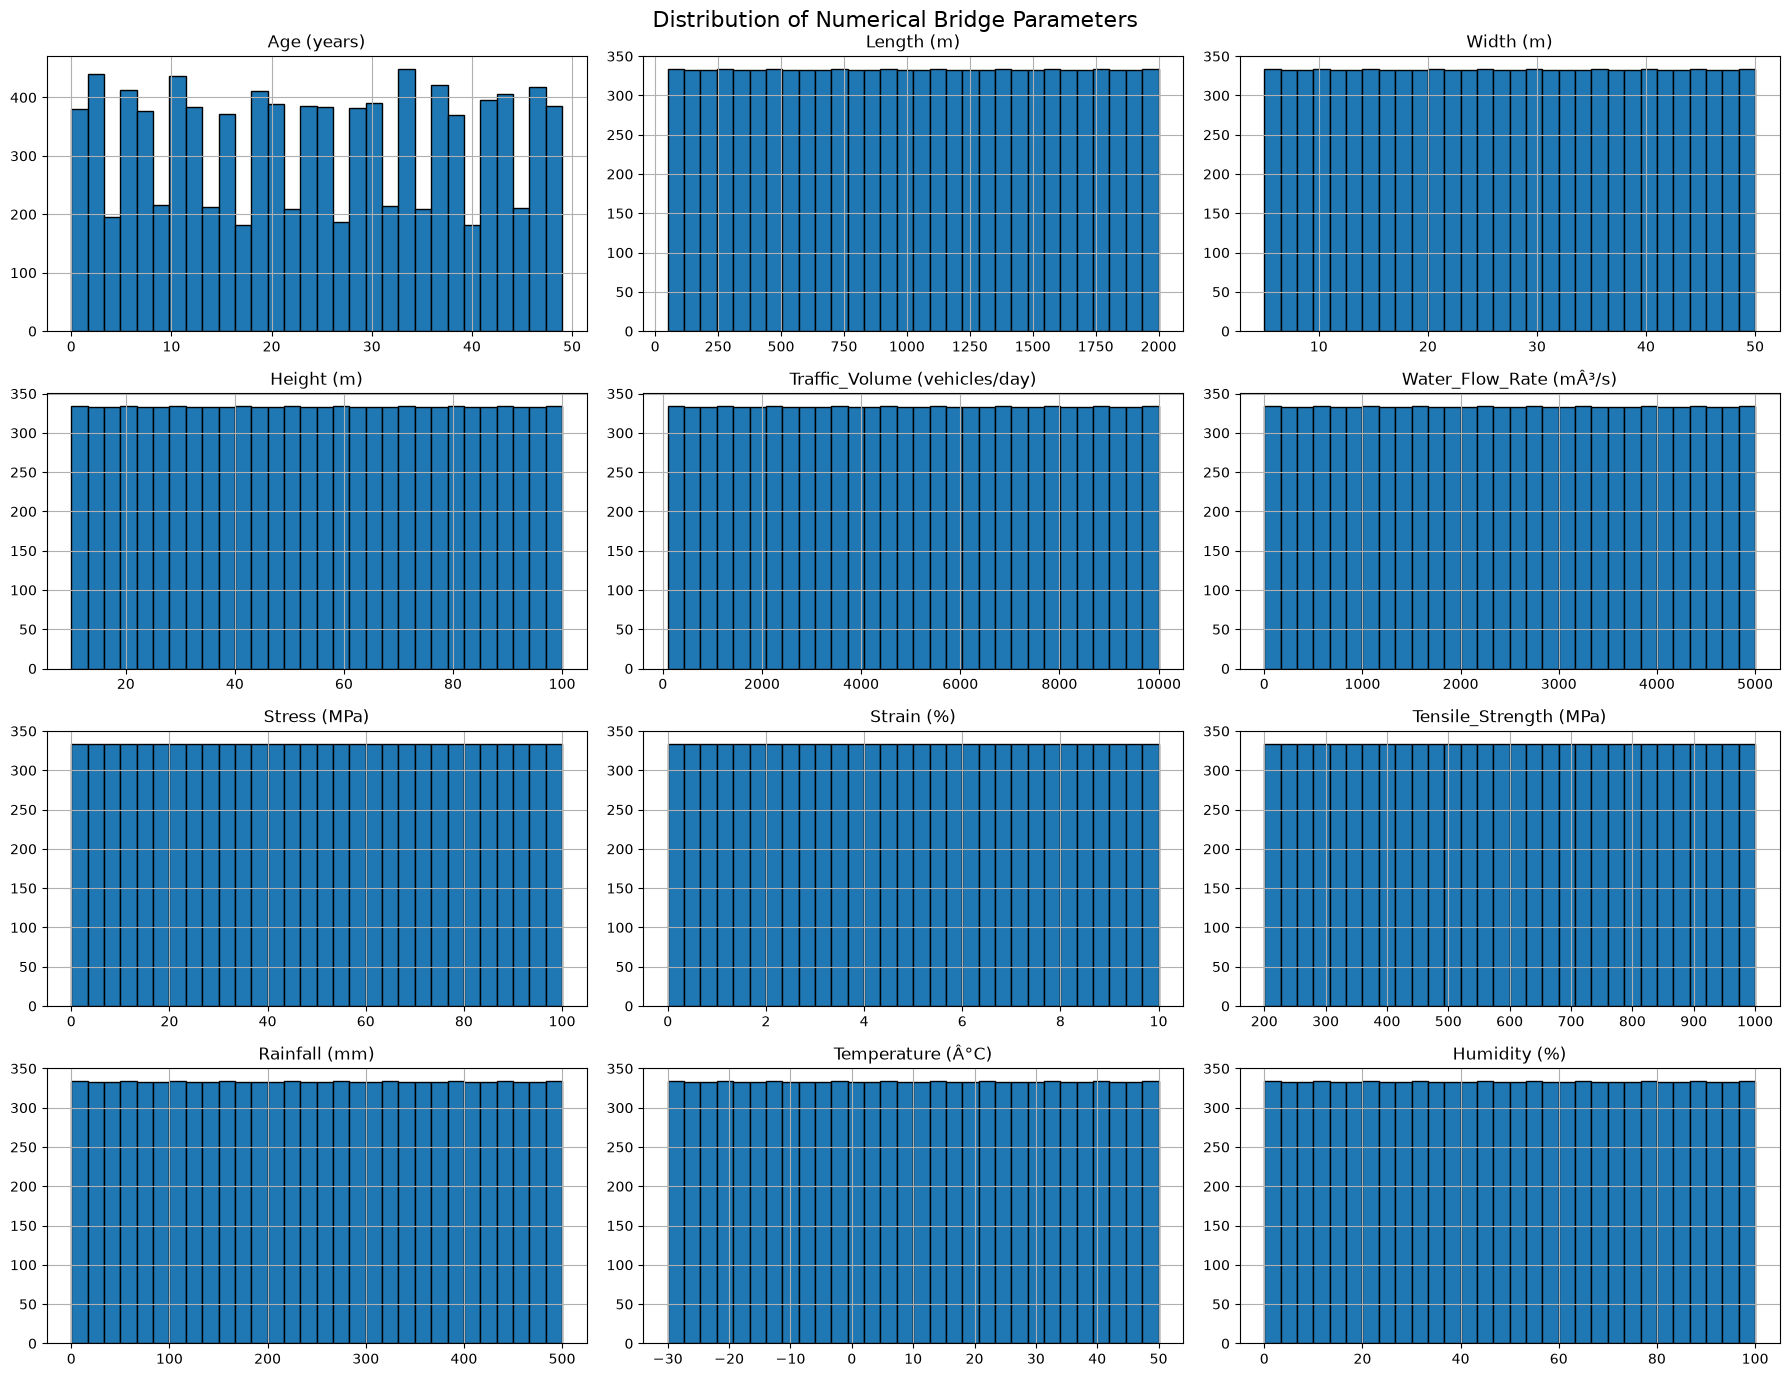

In [19]:

# Cell 12: Plot distributions of numerical features

plot_cols = [
    col for col in numeric_cols
    if col != "Bridge_ID"
]

bridge_df[plot_cols].hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Bridge Parameters",
    fontsize=16
)
plt.tight_layout()
plt.show()


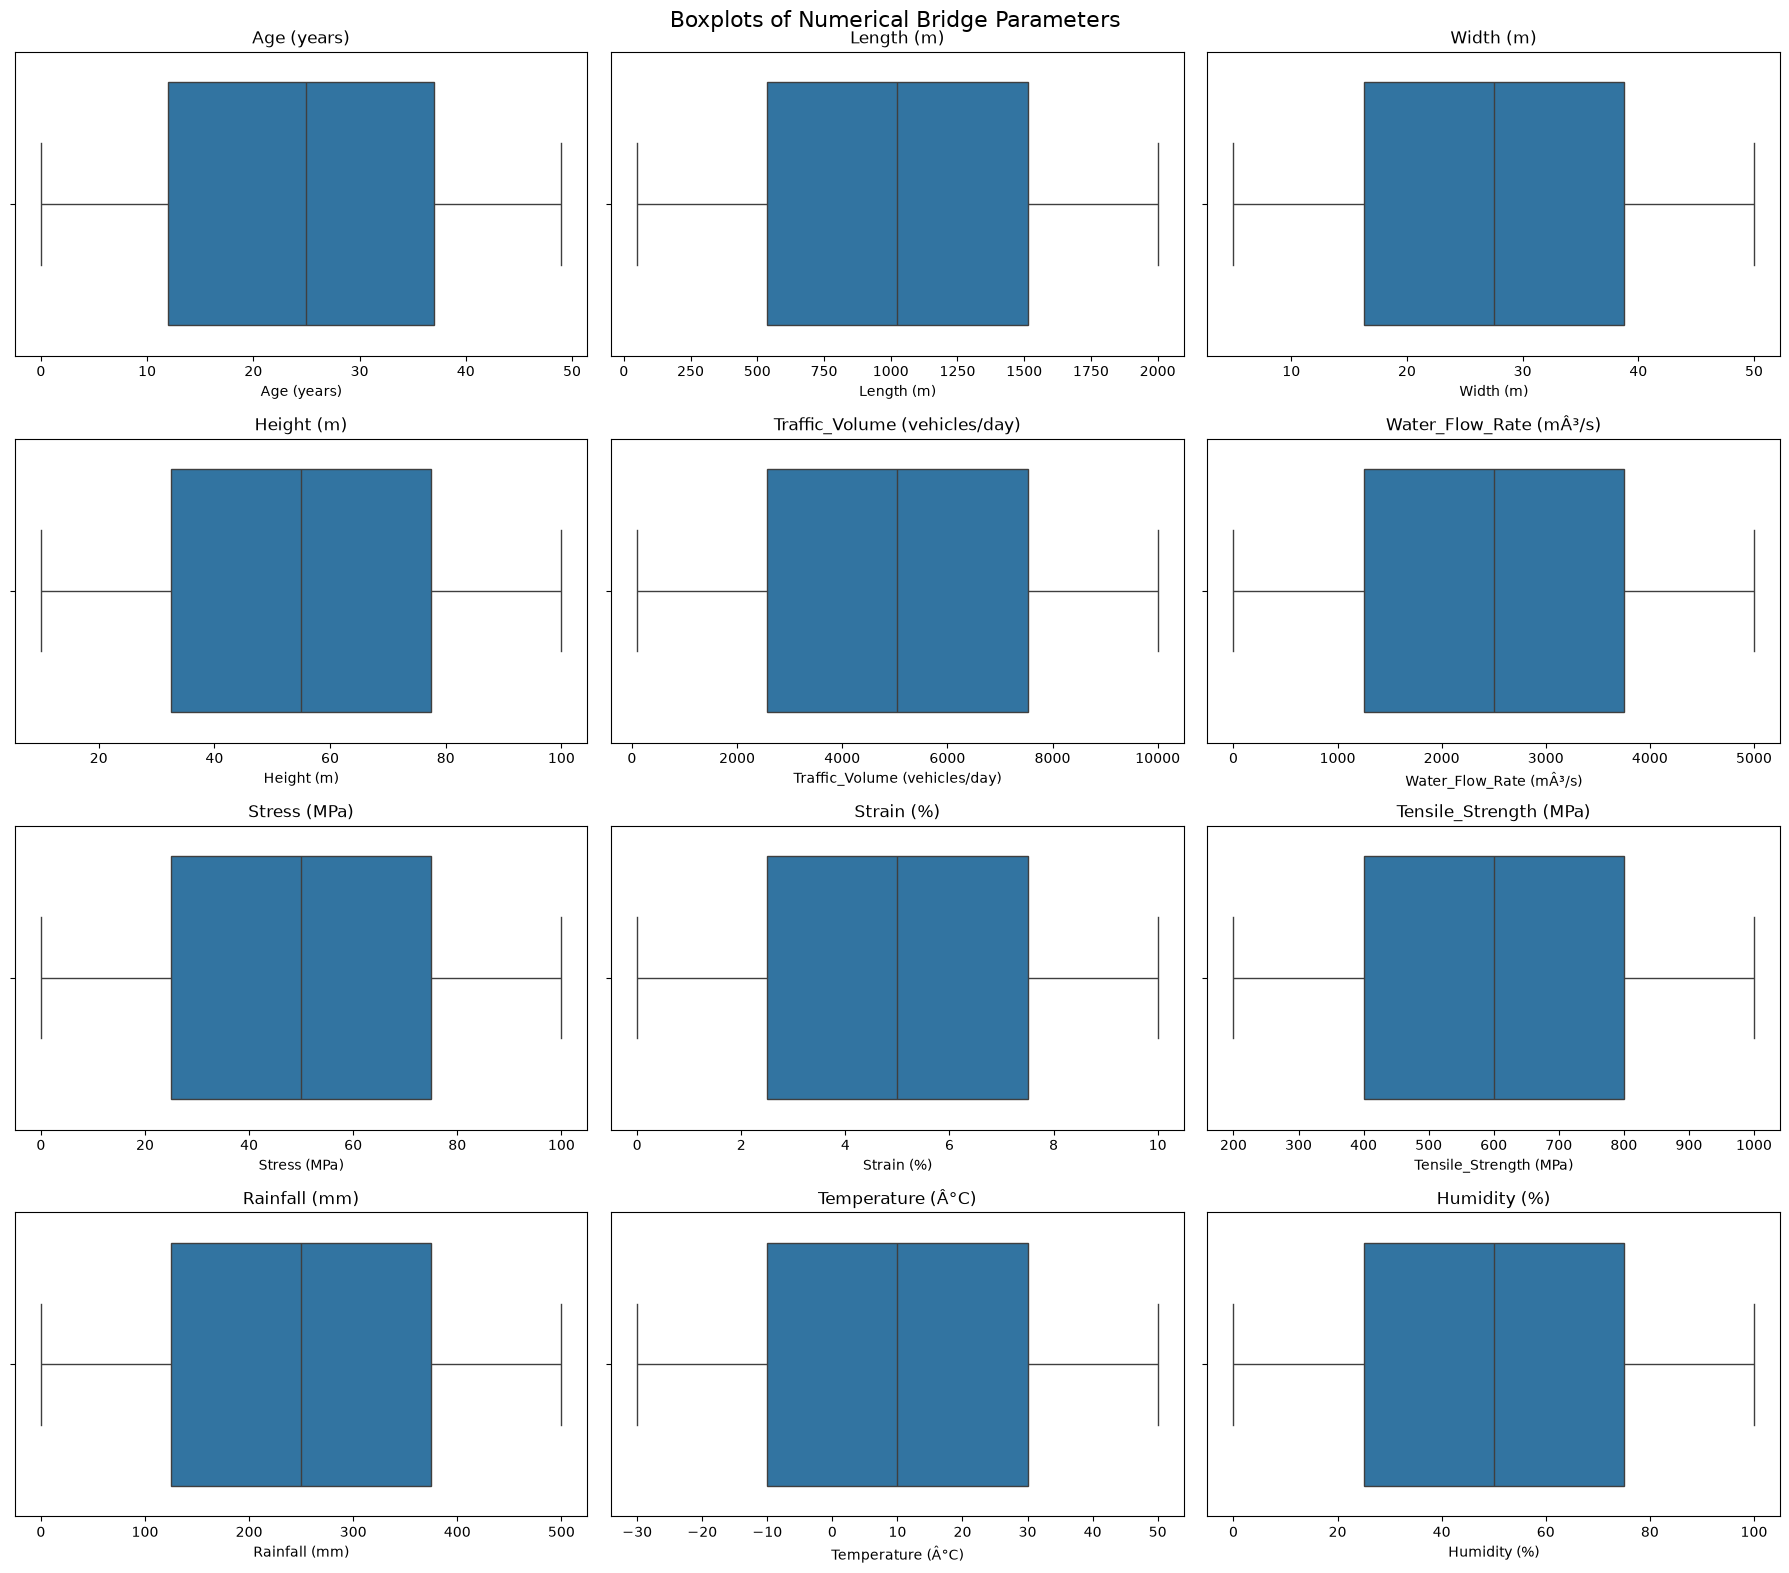

In [20]:

# Cell 13: Boxplots for numerical bridge parameters

plot_cols = [
    col for col in numeric_cols
    if col != "Bridge_ID"
]

n_cols = 3
n_rows = (len(plot_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(plot_cols):
    sns.boxplot(
        x=bridge_df[col],
        ax=axes[i]
    )
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Boxplots of Numerical Bridge Parameters", fontsize=16)
plt.tight_layout()
plt.show()


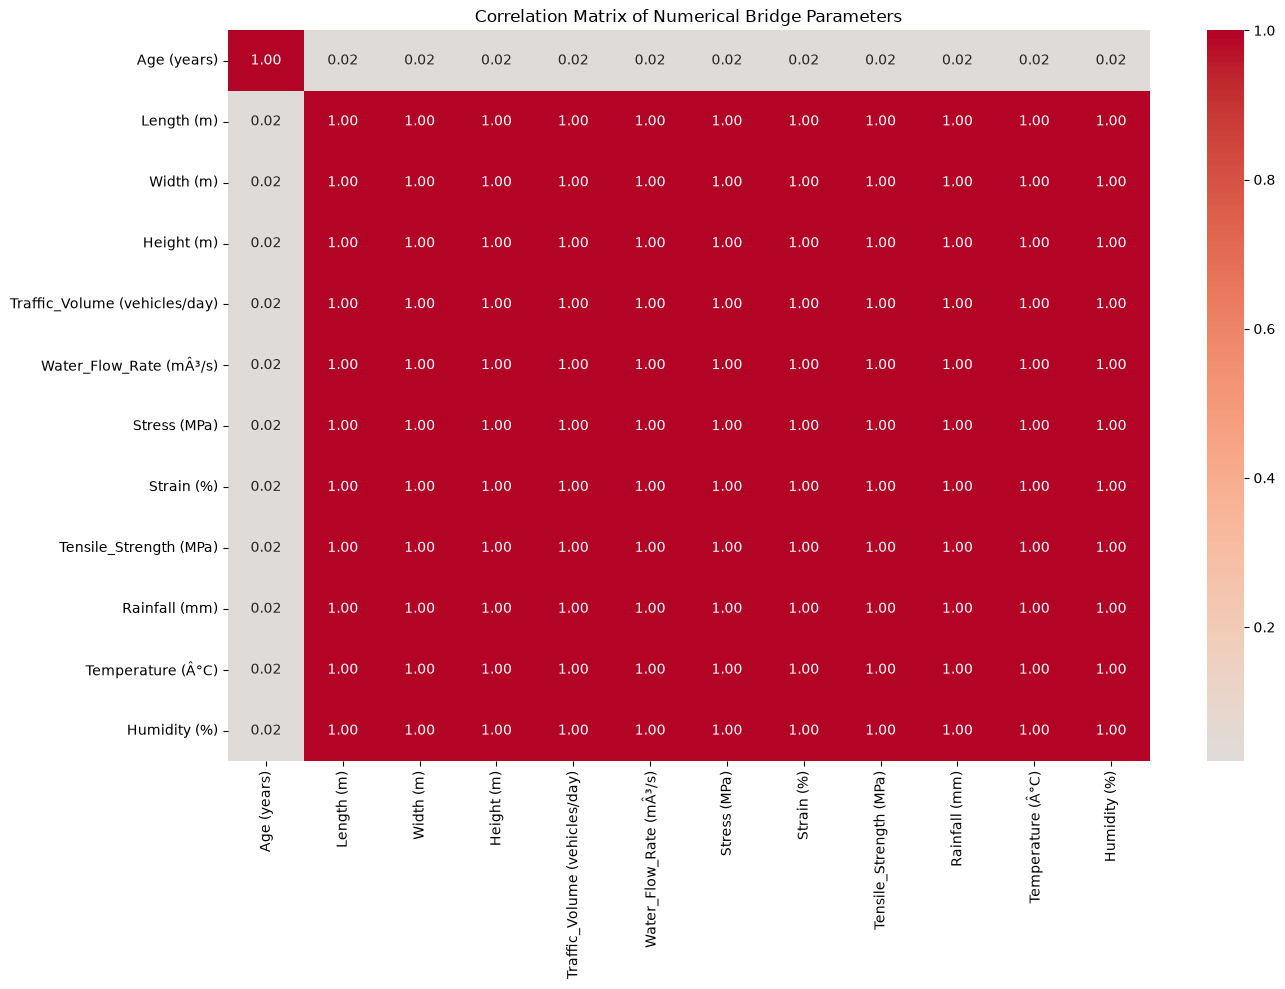

In [21]:

# Cell 14: Correlation matrix for numerical features

corr_cols = [
    col for col in numeric_cols
    if col != "Bridge_ID"
]

correlation_matrix = bridge_df[corr_cols].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Bridge Parameters")
plt.tight_layout()
plt.show()


Target class counts:


,Count
Collapse_Status,
Standing,8000
Collapsed,2000



Target class percentages:


,Percentage (%)
Collapse_Status,
Standing,80.0
Collapsed,20.0


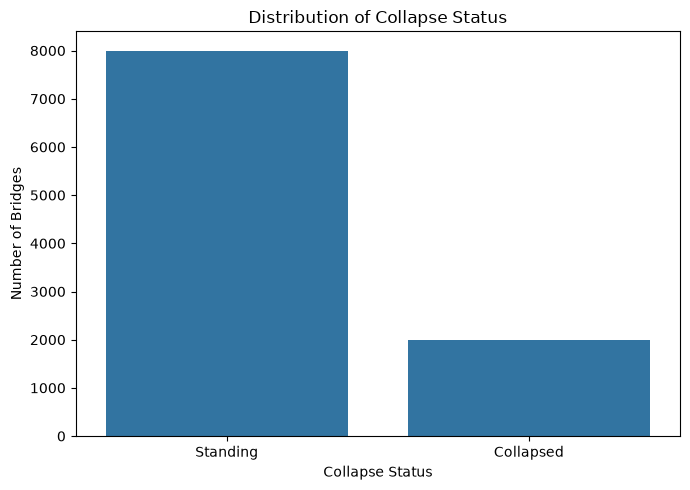

In [22]:

# Cell 15: Analyze target class distribution

print("Target class counts:")
display(bridge_df["Collapse_Status"].value_counts().to_frame("Count"))

print("\nTarget class percentages:")
display(
    (
        bridge_df["Collapse_Status"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .to_frame("Percentage (%)")
    )
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=bridge_df,
    x="Collapse_Status"
)

plt.title("Distribution of Collapse Status")
plt.xlabel("Collapse Status")
plt.ylabel("Number of Bridges")
plt.tight_layout()
plt.show()


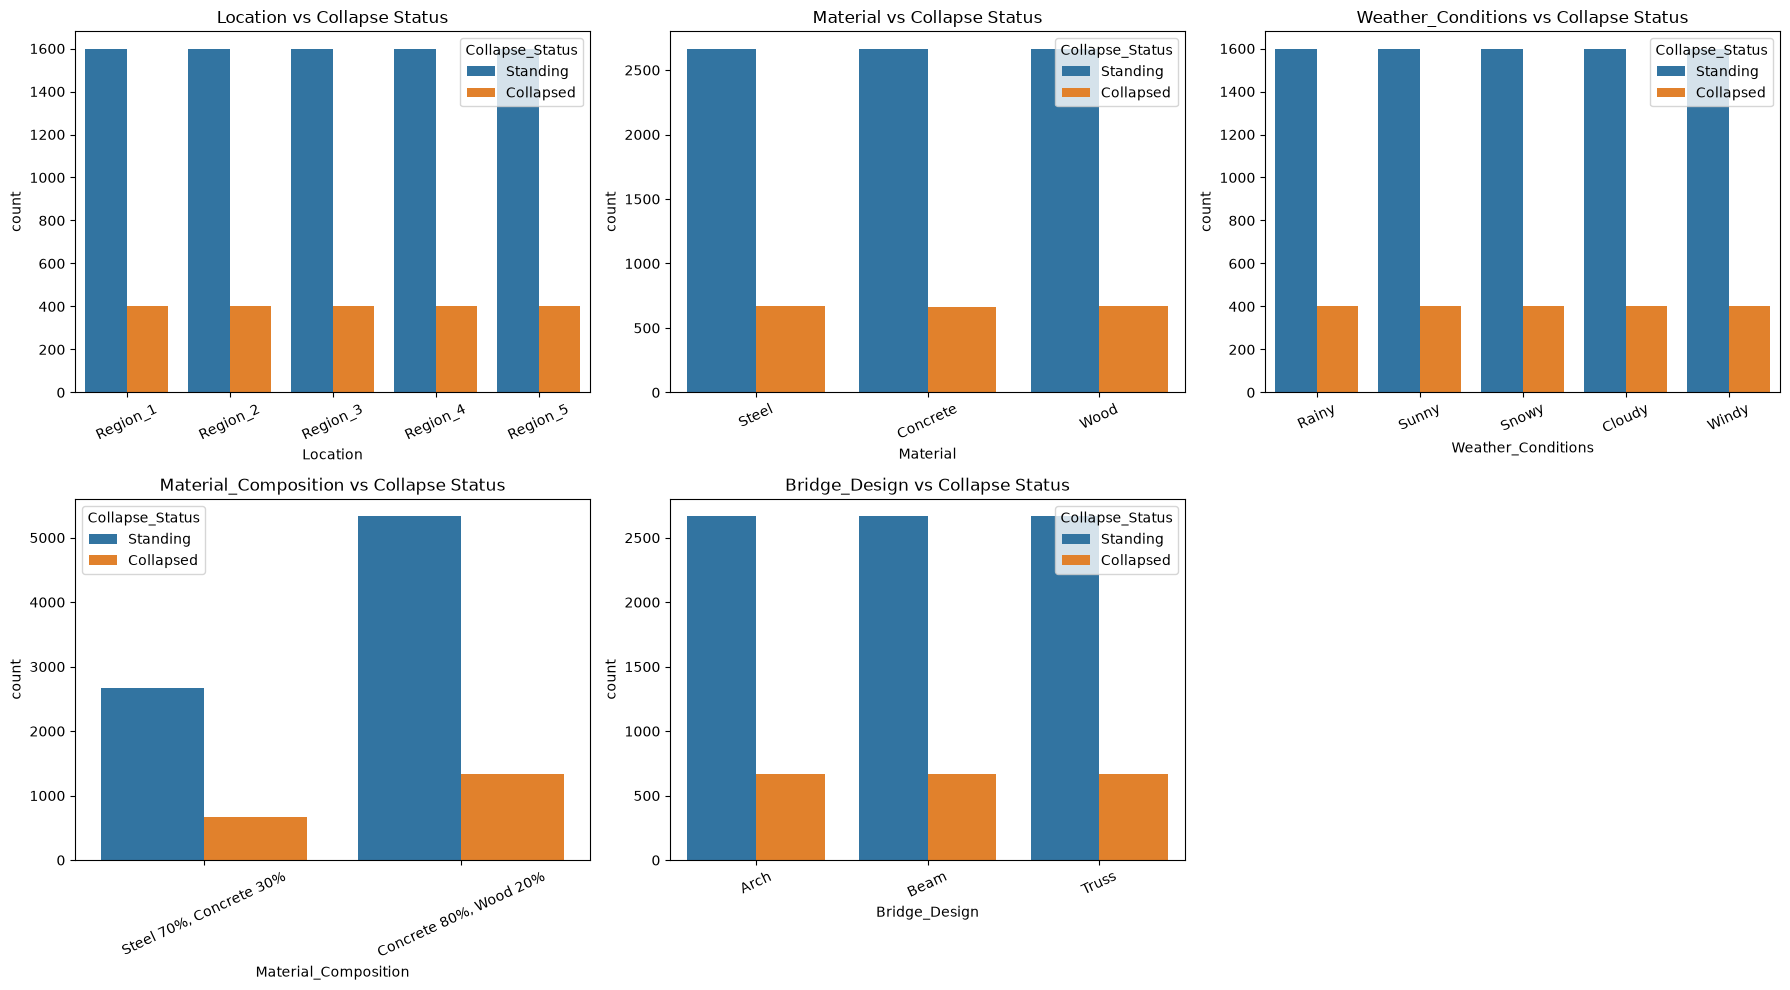

In [23]:

# Cell 16: Compare categorical features with Collapse Status

categorical_features = [
    "Location",
    "Material",
    "Weather_Conditions",
    "Material_Composition",
    "Bridge_Design"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(
        data=bridge_df,
        x=col,
        hue="Collapse_Status",
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs Collapse Status")
    axes[i].tick_params(axis="x", rotation=25)

for j in range(len(categorical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


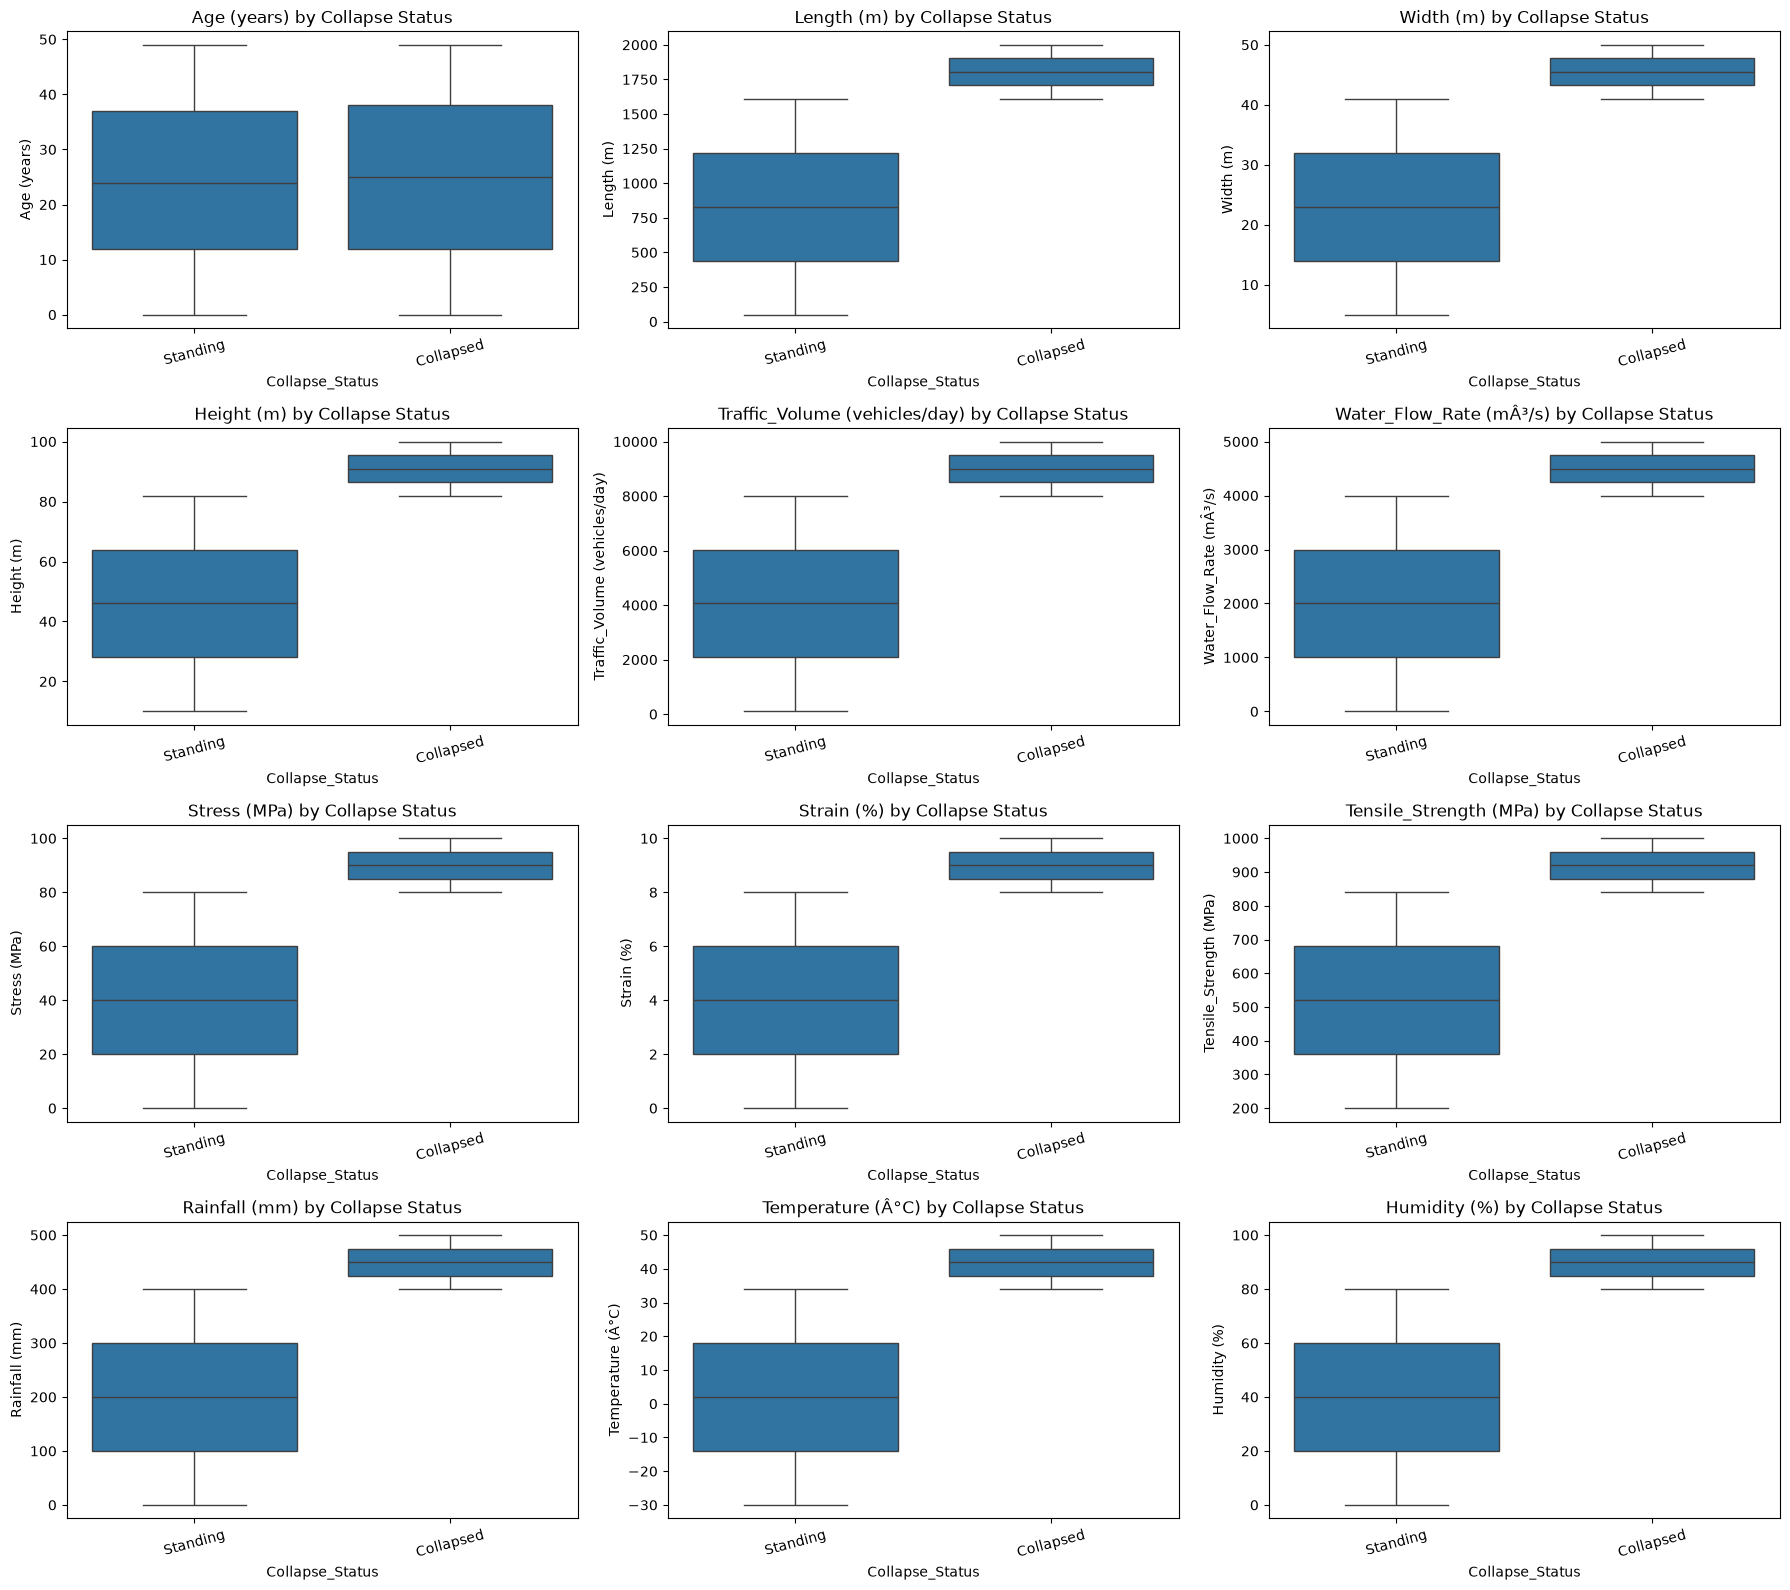

In [24]:

# Cell 17: Compare numerical parameters by Collapse Status

numerical_features = [
    col for col in numeric_cols
    if col != "Bridge_ID"
]

n_cols = 3
n_rows = (len(numerical_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(
        data=bridge_df,
        x="Collapse_Status",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} by Collapse Status")
    axes[i].tick_params(axis="x", rotation=15)

for j in range(len(numerical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


In [25]:

# Cell 18: Count potential outliers using the IQR method

outlier_results = []

for col in numerical_features:
    Q1 = bridge_df[col].quantile(0.25)
    Q3 = bridge_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (bridge_df[col] < lower_bound) |
        (bridge_df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Potential Outliers": int(outlier_count)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)


,Feature,Lower Bound,Upper Bound,Potential Outliers
0,Age (years),-25.5,74.5,0
1,Length (m),-925.0,2975.0,0
2,Width (m),-17.5,72.5,0
3,Height (m),-35.0,145.0,0
4,Traffic_Volume (vehicles/day),-4850.0,14950.0,0
5,Water_Flow_Rate (mÂ³/s),-2500.0,7500.0,0
6,Stress (MPa),-50.0,150.0,0
7,Strain (%),-5.0,15.0,0
8,Tensile_Strength (MPa),-200.0,1400.0,0
9,Rainfall (mm),-250.0,750.0,0


In [26]:

# Cell 19: Inspect Maintenance_History format

print("Data type:")
print(bridge_df["Maintenance_History"].dtype)

print("\nFirst 15 values:")
display(bridge_df["Maintenance_History"].head(15))

print("\nSample unique values:")
display(bridge_df["Maintenance_History"].drop_duplicates().head(10))


Data type:
datetime64[us]

First 15 values:


0    2010-01-01
1    2010-01-02
2    2010-01-03
3    2010-01-04
4    2010-01-05
5    2010-01-06
6    2010-01-07
7    2010-01-08
8    2010-01-09
9    2010-01-10
10   2010-01-11
11   2010-01-12
12   2010-01-13
13   2010-01-14
14   2010-01-15
Name: Maintenance_History, dtype: datetime64[us]


Sample unique values:


0   2010-01-01
1   2010-01-02
2   2010-01-03
3   2010-01-04
4   2010-01-05
5   2010-01-06
6   2010-01-07
7   2010-01-08
8   2010-01-09
9   2010-01-10
Name: Maintenance_History, dtype: datetime64[us]

In [27]:

# Cell 20: Extract date-based features

bridge_df["Maintenance_Year"] = (
    bridge_df["Maintenance_History"].dt.year
)

bridge_df["Maintenance_Month"] = (
    bridge_df["Maintenance_History"].dt.month
)

bridge_df["Maintenance_Day"] = (
    bridge_df["Maintenance_History"].dt.day
)

print("Extracted maintenance date features:")
display(
    bridge_df[
        [
            "Maintenance_History",
            "Maintenance_Year",
            "Maintenance_Month",
            "Maintenance_Day"
        ]
    ].head(10)
)


Extracted maintenance date features:


,Maintenance_History,Maintenance_Year,Maintenance_Month,Maintenance_Day
0,2010-01-01,2010,1,1
1,2010-01-02,2010,1,2
2,2010-01-03,2010,1,3
3,2010-01-04,2010,1,4
4,2010-01-05,2010,1,5
5,2010-01-06,2010,1,6
6,2010-01-07,2010,1,7
7,2010-01-08,2010,1,8
8,2010-01-09,2010,1,9
9,2010-01-10,2010,1,10


In [28]:

# Cell 21: Check maintenance date range and date-feature diversity

print(
    "Earliest maintenance date:",
    bridge_df["Maintenance_History"].min()
)

print(
    "Latest maintenance date:",
    bridge_df["Maintenance_History"].max()
)

print(
    "Unique years:",
    bridge_df["Maintenance_Year"].nunique()
)

print(
    "Unique months:",
    bridge_df["Maintenance_Month"].nunique()
)

print(
    "Unique days:",
    bridge_df["Maintenance_Day"].nunique()
)

print("\nRecords per maintenance year:")
display(bridge_df["Maintenance_Year"].value_counts().sort_index())


Earliest maintenance date: 2010-01-01 00:00:00
Latest maintenance date: 2037-05-18 00:00:00
Unique years: 28
Unique months: 12
Unique days: 31

Records per maintenance year:


Maintenance_Year
2010    365
2011    365
2012    366
2013    365
2014    365
2015    365
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
2025    365
2026    365
2027    365
2028    366
2029    365
2030    365
2031    365
2032    366
2033    365
2034    365
2035    365
2036    366
2037    138
Name: count, dtype: int64

Collapse status percentage by maintenance year:


Collapse_Status,Collapsed,Standing
Maintenance_Year,,
2010,0.00,100.00
2011,0.00,100.00
2012,0.00,100.00
2013,0.00,100.00
2014,0.00,100.00
2015,0.00,100.00
2016,0.00,100.00
2017,0.00,100.00
2018,0.00,100.00


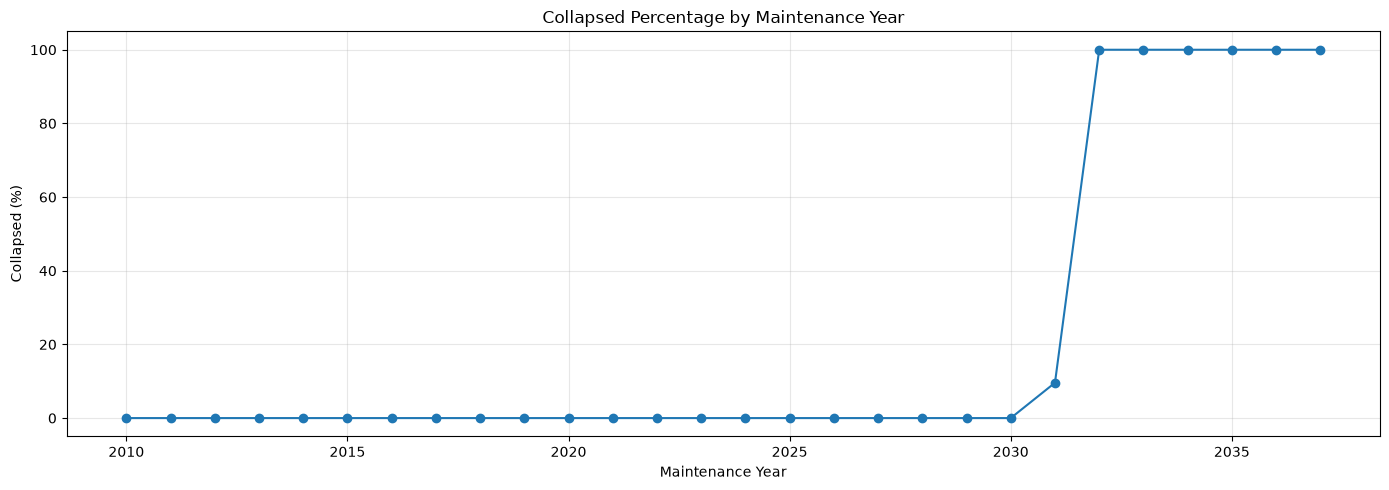

In [29]:

# Cell 22: Check collapse distribution by maintenance year

year_status = pd.crosstab(
    bridge_df["Maintenance_Year"],
    bridge_df["Collapse_Status"],
    normalize="index"
).mul(100).round(2)

print("Collapse status percentage by maintenance year:")
display(year_status)

# Visualize collapsed percentage by year
if "Collapsed" in year_status.columns:
    plt.figure(figsize=(14, 5))
    plt.plot(
        year_status.index,
        year_status["Collapsed"],
        marker="o"
    )
    plt.title("Collapsed Percentage by Maintenance Year")
    plt.xlabel("Maintenance Year")
    plt.ylabel("Collapsed (%)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No 'Collapsed' category found. Check target labels.")


In [30]:

# Cell 23: Check collapse rate across categorical features

categorical_features = [
    "Location",
    "Material",
    "Weather_Conditions",
    "Material_Composition",
    "Bridge_Design"
]

for col in categorical_features:
    print(f"\nCollapse percentage by {col}:")

    collapse_rate = pd.crosstab(
        bridge_df[col],
        bridge_df["Collapse_Status"],
        normalize="index"
    ).mul(100).round(2)

    display(collapse_rate)



Collapse percentage by Location:


Collapse_Status,Collapsed,Standing
Location,,
Region_1,20.0,80.0
Region_2,20.0,80.0
Region_3,20.0,80.0
Region_4,20.0,80.0
Region_5,20.0,80.0



Collapse percentage by Material:


Collapse_Status,Collapsed,Standing
Material,,
Concrete,19.98,80.02
Steel,20.01,79.99
Wood,20.01,79.99



Collapse percentage by Weather_Conditions:


Collapse_Status,Collapsed,Standing
Weather_Conditions,,
Cloudy,20.0,80.0
Rainy,20.0,80.0
Snowy,20.0,80.0
Sunny,20.0,80.0
Windy,20.0,80.0



Collapse percentage by Material_Composition:


Collapse_Status,Collapsed,Standing
Material_Composition,,
"Concrete 80%, Wood 20%",20.00,80.00
"Steel 70%, Concrete 30%",20.01,79.99



Collapse percentage by Bridge_Design:


Collapse_Status,Collapsed,Standing
Bridge_Design,,
Arch,20.01,79.99
Beam,19.98,80.02
Truss,20.01,79.99


In [31]:

# Cell 24: Compare numerical features by collapse status

numerical_features = bridge_df.select_dtypes(
    include=["number"]
).columns.tolist()

# Remove ID and constant columns from analysis
numerical_features = [
    col for col in numerical_features
    if col not in ["Bridge_ID"]
    and bridge_df[col].nunique() > 1
]

for col in numerical_features:
    print(f"\n{col} — summary by Collapse_Status:")

    display(
        bridge_df.groupby("Collapse_Status")[col]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )



Age (years) — summary by Collapse_Status:


,count,mean,median,std,min,max
Collapse_Status,,,,,,
Collapsed,2000,24.85,25.0,14.79,0,49
Standing,8000,24.39,24.0,14.40,0,49



Length (m) — summary by Collapse_Status:


,count,mean,median,std,min,max
Collapse_Status,,,,,,
Collapsed,2000,1805.08,1805.08,112.62,1610.16,2000.00
Standing,8000,829.98,829.98,450.41,50.00,1609.96



Width (m) — summary by Collapse_Status:


...

,count,mean,median,std,min,max
Collapse_Status,,,,,,
Collapsed,2000,2034.15,2034.0,1.61,2031,2037
Standing,8000,2020.45,2020.0,6.32,2010,2031



Maintenance_Month — summary by Collapse_Status:


,count,mean,median,std,min,max
Collapse_Status,,,,,,
Collapsed,2000,6.36,6.0,3.52,1,12
Standing,8000,6.50,7.0,3.44,1,12



Maintenance_Day — summary by Collapse_Status:


,count,mean,median,std,min,max
Collapse_Status,,,,,,
Collapsed,2000,15.70,16.0,8.8,1,31
Standing,8000,15.72,16.0,8.8,1,31


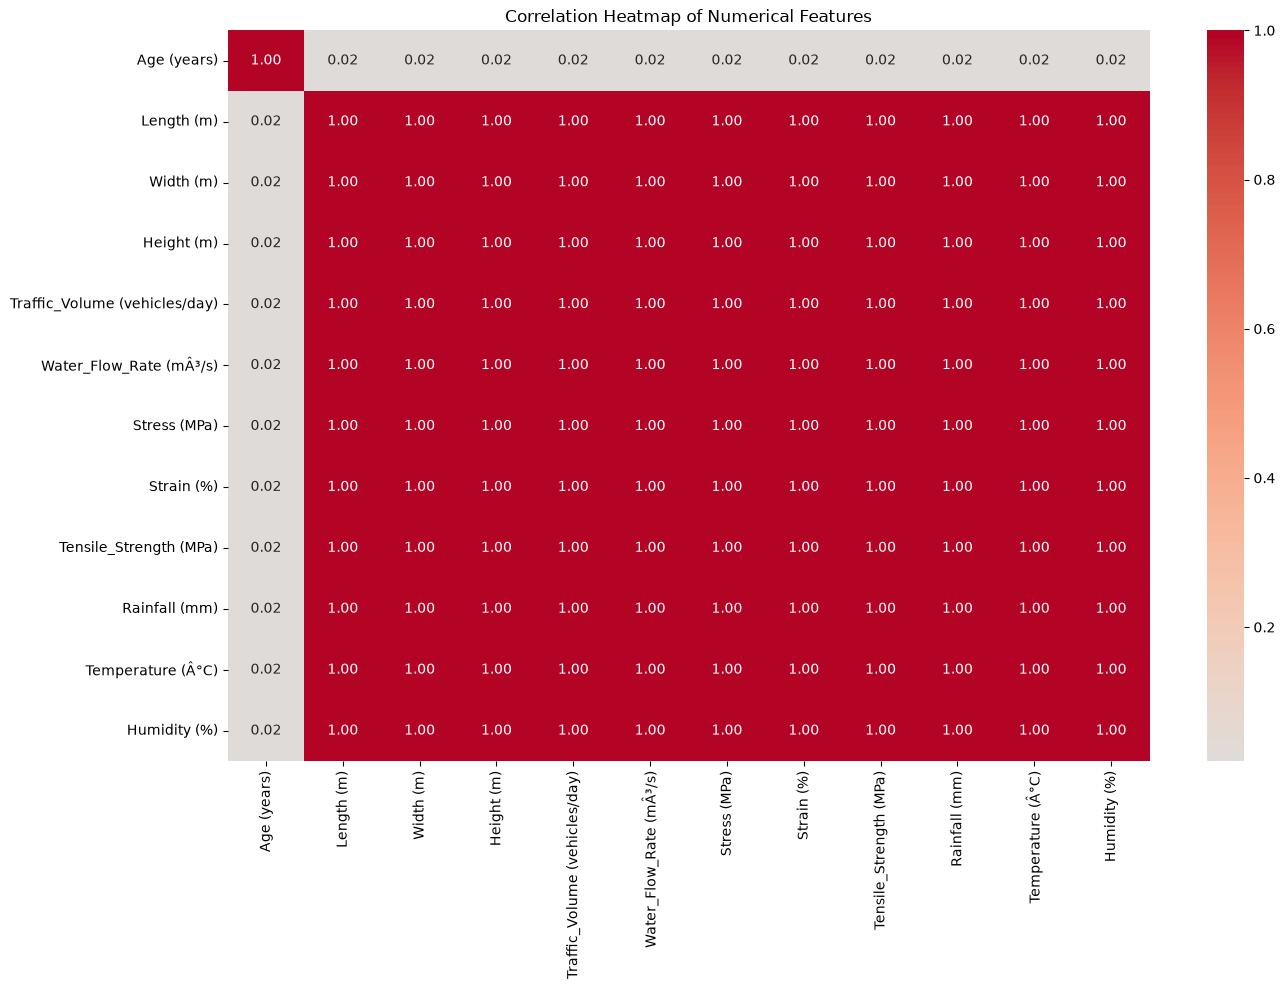

In [32]:

# Cell 25: Correlation heatmap of numerical features

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude identifiers and maintenance date-derived columns
exclude_cols = [
    "Bridge_ID",
    "Maintenance_Year",
    "Maintenance_Month",
    "Maintenance_Day"
]

corr_features = [
    col for col in bridge_df.select_dtypes(include="number").columns
    if col not in exclude_cols
]

correlation_matrix = bridge_df[corr_features].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [33]:

# Cell 26: Prepare features (X) and target (y)

# Columns that should not be used as model inputs
drop_cols = [
    "Bridge_ID",
    "Maintenance_History",
    "Maintenance_Year",
    "Maintenance_Month",
    "Maintenance_Day",
    "Construction_Quality",
    "Collapse_Status"
]

# Create feature matrix and target
X = bridge_df.drop(columns=drop_cols, errors="ignore").copy()
y = bridge_df["Collapse_Status"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures included:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))


Feature matrix shape: (10000, 17)
Target shape: (10000,)

Features included:
['Location', 'Age (years)', 'Material', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Weather_Conditions', 'Water_Flow_Rate (mÂ³/s)', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Material_Composition', 'Bridge_Design', 'Temperature (Â°C)', 'Humidity (%)']

Target distribution:
Collapse_Status
Standing     8000
Collapsed    2000
Name: count, dtype: int64

Target percentages:
Collapse_Status
Standing     80.0
Collapsed    20.0
Name: proportion, dtype: float64


In [34]:

# Cell 27: Filter dataset for concrete bridges

concrete_df = bridge_df[
    bridge_df["Material"].astype(str).str.strip().str.lower() == "concrete"
].copy()

print("Original dataset shape:", bridge_df.shape)
print("Concrete-only dataset shape:", concrete_df.shape)

print("\nMaterial values:")
print(concrete_df["Material"].value_counts())

print("\nMaterial composition values:")
print(concrete_df["Material_Composition"].value_counts())

print("\nCollapse status distribution:")
print(concrete_df["Collapse_Status"].value_counts())

print("\nCollapse status percentages:")
print(
    (concrete_df["Collapse_Status"].value_counts(normalize=True) * 100)
    .round(2)
)


Original dataset shape: (10000, 24)
Concrete-only dataset shape: (3333, 24)

Material values:
Material
Concrete    3333
Name: count, dtype: int64

Material composition values:
Material_Composition
Concrete 80%, Wood 20%    3333
Name: count, dtype: int64

Collapse status distribution:
Collapse_Status
Standing     2667
Collapsed     666
Name: count, dtype: int64

Collapse status percentages:
Collapse_Status
Standing     80.02
Collapsed    19.98
Name: proportion, dtype: float64


In [35]:

# Cell 28: Prepare final features and target for concrete bridges

drop_cols = [
    "Bridge_ID",
    "Material",
    "Material_Composition",
    "Maintenance_History",
    "Maintenance_Year",
    "Maintenance_Month",
    "Maintenance_Day",
    "Construction_Quality",
    "Collapse_Status"
]

X = concrete_df.drop(columns=drop_cols, errors="ignore").copy()
y = concrete_df["Collapse_Status"].copy()

print("Concrete-only feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFinal feature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nConstant features remaining:")
print(X.columns[X.nunique(dropna=False) <= 1].tolist())


Concrete-only feature matrix shape: (3333, 15)
Target shape: (3333,)

Final feature columns:
['Location', 'Age (years)', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Weather_Conditions', 'Water_Flow_Rate (mÂ³/s)', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Bridge_Design', 'Temperature (Â°C)', 'Humidity (%)']

Target distribution:
Collapse_Status
Standing     2667
Collapsed     666
Name: count, dtype: int64

Target percentages:
Collapse_Status
Standing     80.02
Collapsed    19.98
Name: proportion, dtype: float64

Constant features remaining:
['Bridge_Design']


In [36]:

# Cell 29: Verify bridge design and split the data

from sklearn.model_selection import train_test_split

print("Bridge design values in concrete-only data:")
print(concrete_df["Bridge_Design"].value_counts(dropna=False))

# Remove constant features automatically
constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()

if constant_features:
    print("\nDropping constant features:", constant_features)
    X = X.drop(columns=constant_features)

# Split before fitting any preprocessing or model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Bridge design values in concrete-only data:
Bridge_Design
Beam    3333
Name: count, dtype: int64

Dropping constant features: ['Bridge_Design']

Training feature shape: (2666, 14)
Testing feature shape: (667, 14)

Training target percentages:
Collapse_Status
Standing     80.01
Collapsed    19.99
Name: proportion, dtype: float64

Testing target percentages:
Collapse_Status
Standing     80.06
Collapsed    19.94
Name: proportion, dtype: float64


In [37]:

# Cell 30: Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Preprocessing pipeline created successfully.")


Categorical features: ['Location', 'Weather_Conditions']
Numerical features: ['Age (years)', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Water_Flow_Rate (mÂ³/s)', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Temperature (Â°C)', 'Humidity (%)']
Preprocessing pipeline created successfully.


In [38]:

# Cell 31: Train Random Forest classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train using training data only
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
print("Training samples:", X_train.shape[0])
print("Features before encoding:", X_train.shape[1])


Random Forest model trained successfully!
Training samples: 2666
Features before encoding: 14


Test Accuracy: 1.0000 (100.00%)

Classification Report:
              precision    recall  f1-score   support

   Collapsed       1.00      1.00      1.00       133
    Standing       1.00      1.00      1.00       534

    accuracy                           1.00       667
   macro avg       1.00      1.00      1.00       667
weighted avg       1.00      1.00      1.00       667



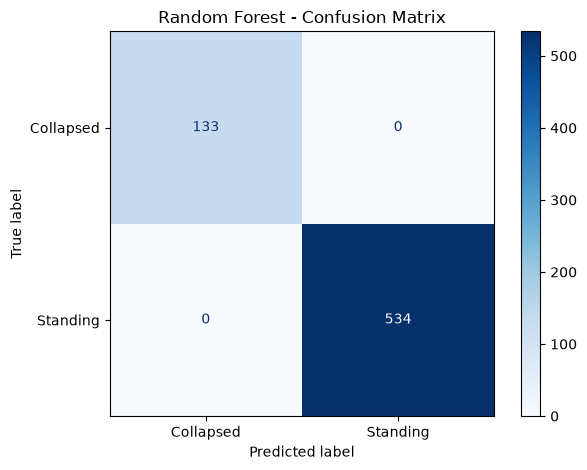

In [39]:

# Cell 32: Evaluate Random Forest on test data

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on unseen test data
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Collapsed", "Standing"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Collapsed", "Standing"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Collapsed", "Standing"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


Top 15 most important features:


,Feature,Importance
2,num__Width (m),0.1110
1,num__Length (m),0.1087
9,num__Rainfall (mm),0.0990
11,num__Humidity (%),0.0950
4,num__Traffic_Volume (vehicles/day),0.0940
7,num__Strain (%),0.0900
5,num__Water_Flow_Rate (mÂ³/s),0.0893
8,num__Tensile_Strength (MPa),0.0829
6,num__Stress (MPa),0.0800
3,num__Height (m),0.0790


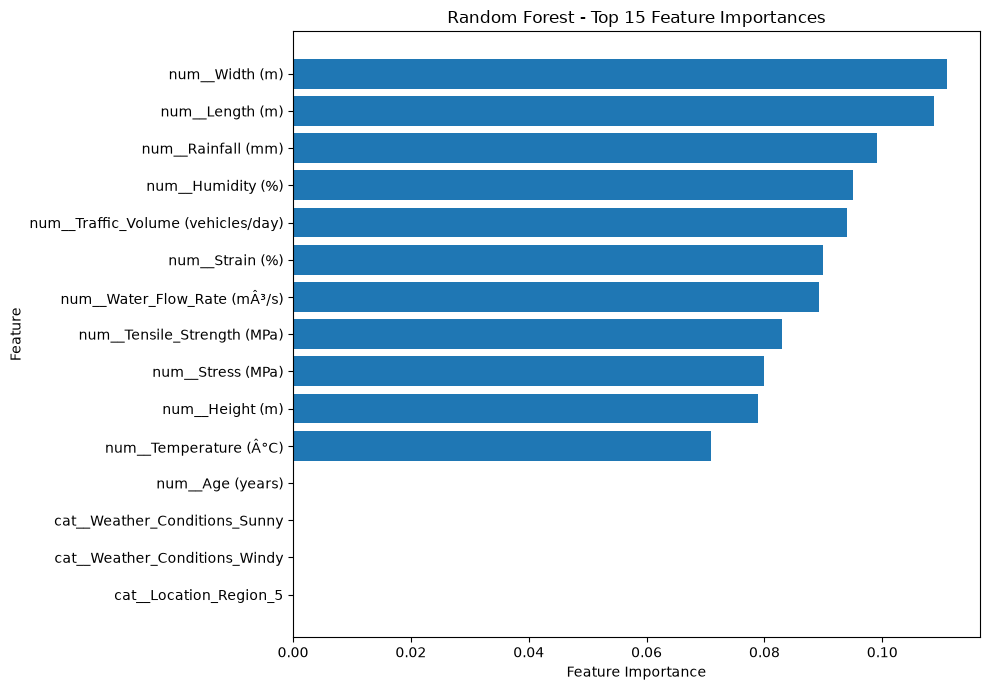

In [40]:

# Cell 33: Plot Random Forest feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get the fitted preprocessing and classifier from the pipeline
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_classifier = rf_model.named_steps["classifier"]

# Get feature names after one-hot encoding
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": fitted_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 most important features:")
display(importance_df.head(15).round(4))

# Plot feature importance
plt.figure(figsize=(10, 7))
top_features = importance_df.head(15).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()


In [41]:

# Cell 34: Save the trained Random Forest pipeline

import joblib
import os

model_path = "bridge_collapse_model.joblib"

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Saved location:", os.path.abspath(model_path))
print("Saved model type:", type(rf_model).__name__)


Model saved successfully!
Saved location: C:\Users\USER\bridge_collapse_model.joblib
Saved model type: Pipeline


In [42]:

# Cell 35: Reload saved model and verify predictions

import joblib
import numpy as np

loaded_model = joblib.load(model_path)

# Compare predictions from original and reloaded model
original_predictions = rf_model.predict(X_test)
reloaded_predictions = loaded_model.predict(X_test)

same_predictions = np.array_equal(
    original_predictions,
    reloaded_predictions
)

print("Model loaded successfully:", type(loaded_model).__name__)
print("Predictions match:", same_predictions)
print("Test samples verified:", len(reloaded_predictions))

if same_predictions:
    print("Verification successful! Saved model works correctly.")
else:
    print("Warning: Predictions differ. Check the saved model.")


Model loaded successfully: Pipeline
Predictions match: True
Test samples verified: 667
Verification successful! Saved model works correctly.


In [43]:

# Cell 36: Copy model into the Streamlit project folder

import os
import shutil

project_dir = r"C:\Users\USER\Documents\Bridge Monitoring System Project"
source_path = os.path.abspath("bridge_collapse_model.joblib")
destination_path = os.path.join(
    project_dir,
    "bridge_collapse_model.joblib"
)

if not os.path.isdir(project_dir):
    print("Project folder not found:", project_dir)
elif not os.path.isfile(source_path):
    print("Source model file not found:", source_path)
else:
    shutil.copy2(source_path, destination_path)
    print("Model copied successfully!")
    print("Destination:", destination_path)
    print("File exists:", os.path.isfile(destination_path))


Model copied successfully!
Destination: C:\Users\USER\Documents\Bridge Monitoring System Project\bridge_collapse_model.joblib
File exists: True


In [44]:

# Cell 37: List files in the Streamlit project folder

import os

project_dir = r"C:\Users\USER\Documents\Bridge Monitoring System Project"

for file_name in sorted(os.listdir(project_dir)):
    full_path = os.path.join(project_dir, file_name)

    if os.path.isfile(full_path):
        size_kb = os.path.getsize(full_path) / 1024
        print(f"{file_name}  ({size_kb:.1f} KB)")
    else:
        print(f"{file_name}/  [folder]")


D/  [folder]
DATA_Maguire_20180517_ALL/  [folder]
P/  [folder]
W/  [folder]
bridge_app.py  (6.3 KB)
bridge_collapse_model.joblib  (156.7 KB)
run_app.bat  (0.1 KB)


In [45]:

# Cell 38: Read existing Streamlit app without modifying it

app_path = r"C:\Users\USER\Documents\Bridge Monitoring System Project\bridge_app.py"

with open(app_path, "r", encoding="utf-8") as file:
    app_code = file.read()

print(app_code)


# Bridge Health Monitoring System - Professional UI

import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

# Page configuration
st.set_page_config(
    page_title="Bridge Health Monitoring System",
    page_icon="🌉",
    layout="centered"
)

# Custom CSS for professional bridge-themed UI
st.markdown("""
<style>

    /* Main background */
    .stApp {
        background: linear-gradient(
            135deg,
            #e8f1f8 0%,
            #f7fbff 45%,
            #dce9f2 100%
        );
    }

    /* Main title */
    .main-title {
        text-align: center;
        color: #12344d;
        font-size: 42px;
        font-weight: 800;
        margin-top: 10px;
        margin-bottom: 5px;
    }

    /* Subtitle */
    .subtitle {
        text-align: center;
        color: #4b6475;
        font-size: 20px;
        margin-bottom: 25px;
    }

    /* Project description card */
    .info-card {
        background: rgba(255, 255, 255, 0.85);
        paddi

In [46]:

# Cell 39: Verify collapse model file and joblib

import os
import joblib

project_dir = r"C:\Users\USER\Documents\Bridge Monitoring System Project"
collapse_model_path = os.path.join(
    project_dir,
    "bridge_collapse_model.joblib"
)

print("Collapse model exists:", os.path.isfile(collapse_model_path))
print("Model path:", collapse_model_path)

try:
    test_model = joblib.load(collapse_model_path)
    print("Model loaded successfully:", type(test_model).__name__)
except Exception as e:
    print("Model loading error:", repr(e))


Collapse model exists: True
Model path: C:\Users\USER\Documents\Bridge Monitoring System Project\bridge_collapse_model.joblib
Model loaded successfully: Pipeline


In [47]:

print("Expected input features:")
print(test_model.feature_names_in_.tolist())

print("\nModel classes:")
print(test_model.classes_)


Expected input features:
['Location', 'Age (years)', 'Length (m)', 'Width (m)', 'Height (m)', 'Traffic_Volume (vehicles/day)', 'Weather_Conditions', 'Water_Flow_Rate (mÂ³/s)', 'Stress (MPa)', 'Strain (%)', 'Tensile_Strength (MPa)', 'Rainfall (mm)', 'Temperature (Â°C)', 'Humidity (%)']

Model classes:
['Collapsed' 'Standing']


In [48]:

import os
import joblib
import pandas as pd
